# Proyecto integrador de Ciencia de Datos e Inteligencia Artificial

**Fase 3 **  
**Asignatura:** Ciencia de Datos  
**Programa:** Maestría en Inteligencia Artificial  
**Estudiante:** Jennifer Juliana Bayona Rojas

Enlace del notebook: https://colab.research.google.com/drive/1Ao7FCMKKVsbXIZYu7pRa2fHVAGufZn3R?usp=sharing

## Preparación del entorno

Se importan las bibliotecas para manipulación de datos, visualización, preprocesamiento y evaluación de modelos. Se fija la presentación de tablas para facilitar la lectura.

In [1]:
# Manipulación de datos y archivos
import os
import joblib
import pandas as pd
import numpy as np
from copy import deepcopy
from IPython.display import display

# Visualización de datos
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Preprocesamiento y modelos de Machine Learning
from sklearn.model_selection import (
    train_test_split, RandomizedSearchCV,
    KFold, StratifiedKFold
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.svm import LinearSVC
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

# Evaluación e interpretabilidad
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, precision_recall_curve,
    silhouette_score
)
from sklearn.inspection import permutation_importance

# Redes neuronales con PyTorch
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


# Configuración de visualización de tablas
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")


# Función reutilizable para visualizar matrices de confusión
def graficar_matriz_confusion(matriz, titulo):
    fig, ax = plt.subplots(figsize=(6.2, 4.7))

    ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=["Completado (0)", "Devuelto (1)"]
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(titulo, pad=12)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")

    fig.tight_layout()
    plt.show()


## 1. Carga del conjunto de datos

Se utiliza `fase2_para_fase3.joblib`, generado en la celda 54 de la Fase 2. El archivo contiene las particiones de entrenamiento, validación y prueba, las métricas de los modelos base y la tabla de pedidos en USD para segmentación. Usar estas mismas particiones permite comparar los modelos avanzados con las referencias de la fase anterior.

In [2]:
# Descargar el archivo con los resultados de la fase 2
nombre_archivo = 'fase2_para_fase3.joblib'
if not os.path.exists(nombre_archivo):
    !gdown 1wDnzX-a0oHq3XxFnYRXiOUDqfOW4Nyg5 --output $nombre_archivo


Downloading...
From: https://drive.google.com/uc?id=1wDnzX-a0oHq3XxFnYRXiOUDqfOW4Nyg5
To: /content/fase2_para_fase3.joblib
100% 8.80M/8.80M [00:00<00:00, 40.8MB/s]


In [3]:
# Cargar datos preparados en la Fase 2
datos = joblib.load("fase2_para_fase3.joblib")

# Regresión
reg = datos["regresion"]
X_reg_train = reg["X_train"]
X_reg_val = reg["X_val"]
X_reg_test = reg["X_test"]
y_reg_train = reg["y_train"]
y_reg_val = reg["y_val"]
y_reg_test = reg["y_test"]

# Clasificación
clf = datos["clasificacion"]
X_clf_train = clf["X_train"]
X_clf_val = clf["X_val"]
X_clf_test = clf["X_test"]
y_clf_train = clf["y_train"]
y_clf_val = clf["y_val"]
y_clf_test = clf["y_test"]

# Clustering
df_clustering = datos["clustering"]

# Resultados de referencia de la Fase 2
baseline_reg = datos["baseline_regresion"]
baseline_clf = datos["baseline_clasificacion"]

df_master = datos["df_master"].copy()

print("Dimensiones:", df_master.shape)
display(df_master.head())

print("Datos cargados correctamente")


Dimensiones: (138116, 22)


,order_id,customer_id,order_date,currency,customer_age,customer_segment,sales_channel,quantity,net_sales,order_status,customer_country,payment_method,shipping_method,marketing_channel,estimated_delivery_days,delivery_days,loyalty_points_redeemed,review_sentiment,loyalty_points_log,order_month,is_weekend,age_group
0,ORD-301242,CUST-003102,2023-11-06,USD,55,Consumer,Mobile App,5,945.400,Completed,USA,Digital Wallet,Standard,Direct,3.000,3.000,44,Positive,3.807,11,0,45-59
1,ORD-773460,CUST-003124,2025-12-24,EUR,26,Premium,Website,8,"2,018.410",Completed,Germany,Debit Card,Economy,Direct,10.000,10.000,171,Positive,5.147,12,0,18-29
2,ORD-449374,CUST-012496,2021-07-05,USD,69,Premium,Mobile App,5,468.350,Completed,USA,Cash on Delivery,Express,YouTube,3.000,3.000,16,Positive,2.833,7,0,60+
3,ORD-567636,CUST-023928,2023-01-21,USD,65,Consumer,Social Media,2,546.520,Completed,USA,Debit Card,Express,Email Marketing,2.000,2.000,10,Positive,2.398,1,1,60+
4,ORD-820028,CUST-012730,2022-05-13,INR,34,Consumer,Social Media,6,"2,785.270",Completed,India,Digital Wallet,Standard,Direct,5.000,6.000,147,Neutral,4.997,5,0,30-44


Datos cargados correctamente


## 2. Modelado avanzado de regresión

Se implementan modelos de regresión para predecir `net_sales` en USD, utilizando las variables preparadas en la Fase 2.

Se comparan modelos lineales regularizados y algoritmos basados en árboles, evaluando su rendimiento mediante MAE, RMSE y R² frente al modelo baseline.

In [4]:

# Excluir variables potencialmente problemáticas
columnas_excluir_reg = [
    "loyalty_points_log",
    "loyalty_points_redeemed"
]

X_reg_train_f3 = X_reg_train.drop(
    columns=columnas_excluir_reg, errors="ignore"
).copy()

X_reg_val_f3 = X_reg_val.drop(
    columns=columnas_excluir_reg, errors="ignore"
).copy()

X_reg_test_f3 = X_reg_test.drop(
    columns=columnas_excluir_reg, errors="ignore"
).copy()

# Identificar variables numéricas y categóricas
numericas_reg_f3 = X_reg_train_f3.select_dtypes(
    include=np.number
).columns.tolist()

categoricas_reg_f3 = [
    col for col in X_reg_train_f3.columns
    if col not in numericas_reg_f3
]

# Validar consistencia de las particiones
assert X_reg_train_f3.columns.equals(X_reg_val_f3.columns)
assert X_reg_train_f3.columns.equals(X_reg_test_f3.columns)

print("PREPARACIÓN PARA REGRESIÓN")
print("Entrenamiento:", X_reg_train_f3.shape)
print("Validación:", X_reg_val_f3.shape)
print("Prueba:", X_reg_test_f3.shape)

print("\nVariables numéricas:", numericas_reg_f3)
print("Variables categóricas:", categoricas_reg_f3)

print("\nValores faltantes en entrenamiento:",
      X_reg_train_f3.isna().sum().sum())

PREPARACIÓN PARA REGRESIÓN
Entrenamiento: (57820, 10)
Validación: (12390, 10)
Prueba: (12390, 10)

Variables numéricas: ['customer_age', 'quantity', 'order_month', 'is_weekend']
Variables categóricas: ['customer_segment', 'sales_channel', 'customer_country', 'payment_method', 'shipping_method', 'marketing_channel']

Valores faltantes en entrenamiento: 0


In [5]:
# Definir preprocesamiento
preprocesador_ridge = ColumnTransformer([
    ("numericas",
     StandardScaler(),
     numericas_reg_f3),

    ("categoricas",
     OneHotEncoder(handle_unknown="ignore"),
     categoricas_reg_f3)
])

# Crear modelo Ridge
modelo_ridge = Pipeline([
    ("preprocesamiento", preprocesador_ridge),
    ("modelo", Ridge(
        alpha=1.0,
        solver="lsqr"
    ))
])

# Entrenar únicamente con entrenamiento
modelo_ridge.fit(X_reg_train_f3, y_reg_train)

# Realizar predicciones
pred_ridge_train = modelo_ridge.predict(X_reg_train_f3)
pred_ridge_val = modelo_ridge.predict(X_reg_val_f3)

print("MODELO RIDGE ENTRENADO CORRECTAMENTE")

MODELO RIDGE ENTRENADO CORRECTAMENTE


### 2.2. Evaluación del modelo Ridge

Se evalúa el rendimiento en entrenamiento y validación mediante MAE, RMSE y R².

Los resultados se comparan con la regresión lineal simple desarrollada en la Fase 2 para determinar si la incorporación de nuevas variables mejora la capacidad predictiva.

In [6]:
# Función de evaluación
def evaluar_regresion_f3(y_real, y_pred):
    return {
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
        "R2": r2_score(y_real, y_pred)
    }

# Evaluar entrenamiento y validación
resultados_ridge = pd.DataFrame({
    "Entrenamiento": evaluar_regresion_f3(
        y_reg_train, pred_ridge_train
    ),
    "Validación": evaluar_regresion_f3(
        y_reg_val, pred_ridge_val
    )
}).T

print("RESULTADOS - REGRESIÓN RIDGE")
display(resultados_ridge.round(4))

# Comparar con baseline de Fase 2
comparacion_regresion = pd.DataFrame({
    "Regresión lineal simple": baseline_reg.loc["Validación"],
    "Ridge": resultados_ridge.loc["Validación"]
}).T

print("\nCOMPARACIÓN CON BASELINE - VALIDACIÓN")
display(comparacion_regresion.round(4))

# Identificar mejora en RMSE
mejora_rmse = (
    baseline_reg.loc["Validación", "RMSE"]
    - resultados_ridge.loc["Validación", "RMSE"]
)

print(f"\nDiferencia de RMSE: {mejora_rmse:.4f}")

if mejora_rmse > 0:
    print("Ridge reduce el error respecto al baseline.")
else:
    print("Ridge no mejora el RMSE del baseline.")

RESULTADOS - REGRESIÓN RIDGE


,MAE,RMSE,R2
Entrenamiento,621.992,901.674,0.366
Validación,616.934,888.476,0.360



COMPARACIÓN CON BASELINE - VALIDACIÓN


,MAE,RMSE,R2
Regresión lineal simple,619.839,894.064,0.352
Ridge,616.934,888.476,0.360



Diferencia de RMSE: 5.5884
Ridge reduce el error respecto al baseline.


### 2.3. Random Forest Regressor

Se implementa Random Forest Regressor, un algoritmo de ensamble que combina múltiples árboles de decisión para predecir `net_sales`.

A diferencia de Ridge, permite capturar relaciones no lineales e interacciones entre variables. Se limita la profundidad de los árboles y se establece un mínimo de observaciones por hoja para reducir el sobreajuste.

In [7]:
# Preprocesamiento para Random Forest
# Los árboles no requieren estandarización
preprocesador_rf = ColumnTransformer([
    ("numericas", "passthrough", numericas_reg_f3),
    ("categoricas",
     OneHotEncoder(handle_unknown="ignore"),
     categoricas_reg_f3)
])

# Crear pipeline
modelo_rf = Pipeline([
    ("preprocesamiento", preprocesador_rf),
    ("modelo", RandomForestRegressor(
        n_estimators=120,
        max_depth=14,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Entrenar con el conjunto de entrenamiento
modelo_rf.fit(X_reg_train_f3, y_reg_train)

# Predicciones
pred_rf_train = modelo_rf.predict(X_reg_train_f3)
pred_rf_val = modelo_rf.predict(X_reg_val_f3)

print("RANDOM FOREST ENTRENADO CORRECTAMENTE")

RANDOM FOREST ENTRENADO CORRECTAMENTE


### 2.4. Evaluación de Random Forest

Se calculan MAE, RMSE y R² para los conjuntos de entrenamiento y validación.

La comparación entre ambos conjuntos permite identificar posibles señales de sobreajuste y determinar la capacidad de generalización del modelo.

In [8]:
# Evaluar Random Forest
resultados_rf = pd.DataFrame({
    "Entrenamiento": evaluar_regresion_f3(
        y_reg_train, pred_rf_train
    ),
    "Validación": evaluar_regresion_f3(
        y_reg_val, pred_rf_val
    )
}).T

print("RESULTADOS - RANDOM FOREST")
display(resultados_rf.round(4))

# Comparar entrenamiento y validación
diferencia_r2 = (
    resultados_rf.loc["Entrenamiento", "R2"]
    - resultados_rf.loc["Validación", "R2"]
)

print(f"\nDiferencia de R²: {diferencia_r2:.4f}")

if diferencia_r2 > 0.10:
    print("Existe una diferencia considerable entre entrenamiento y validación.")
    print("Se recomienda revisar posible sobreajuste.")
else:
    print("No se observa una diferencia grande de R² entre los conjuntos.")


RESULTADOS - RANDOM FOREST


,MAE,RMSE,R2
Entrenamiento,535.842,773.600,0.534
Validación,614.812,887.951,0.361



Diferencia de R²: 0.1726
Existe una diferencia considerable entre entrenamiento y validación.
Se recomienda revisar posible sobreajuste.


### 2.5. Comparación de los modelos de regresión

Se comparan los tres modelos implementados hasta el momento: regresión lineal simple (baseline), Ridge y Random Forest.

El mejor modelo se seleccionará considerando principalmente el RMSE de validación, complementado con MAE, R² y la diferencia de rendimiento entre entrenamiento y validación.

COMPARACIÓN DE MODELOS - VALIDACIÓN


,MAE,RMSE,R2
Regresión lineal,619.839,894.064,0.352
Ridge,616.934,888.476,0.360
Random Forest,614.812,887.951,0.361


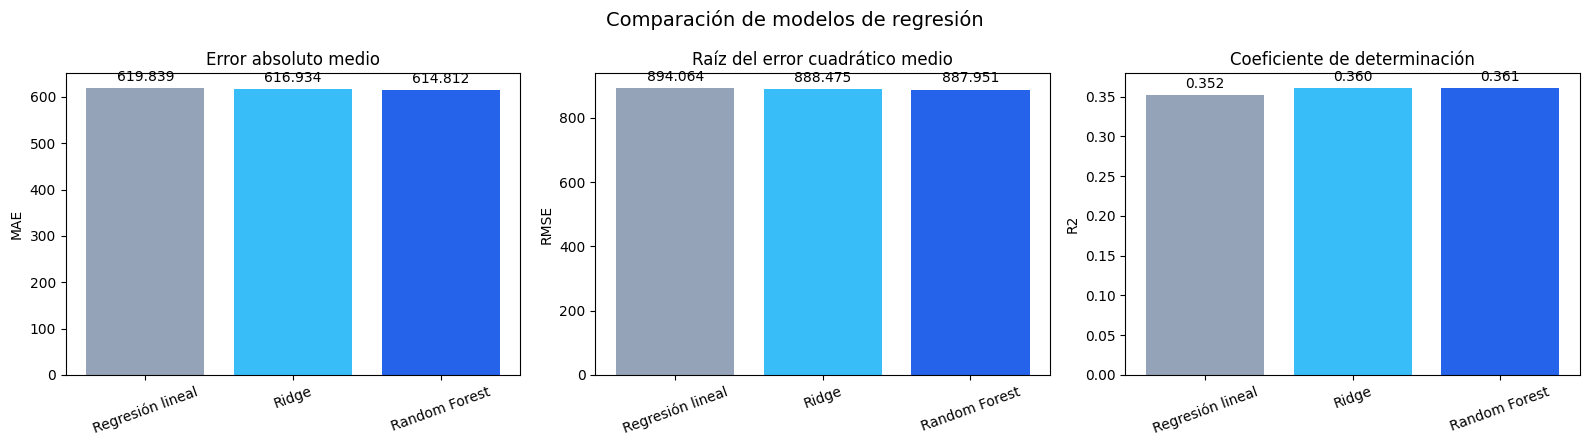


Mejor modelo según RMSE: Random Forest


In [9]:
# Comparar resultados en validación
comparacion_regresion = pd.DataFrame({
    "Regresión lineal": baseline_reg.loc["Validación"],
    "Ridge": resultados_ridge.loc["Validación"],
    "Random Forest": resultados_rf.loc["Validación"]
}).T

print("COMPARACIÓN DE MODELOS - VALIDACIÓN")
display(comparacion_regresion.round(4))

# Visualización de métricas
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

metricas = ["MAE", "RMSE", "R2"]
titulos = ["Error absoluto medio", "Raíz del error cuadrático medio",
           "Coeficiente de determinación"]

for ax, metrica, titulo in zip(axes, metricas, titulos):
    valores = comparacion_regresion[metrica]

    barras = ax.bar(
        valores.index,
        valores.values,
        color=["#94a3b8", "#38bdf8", "#2563eb"]
    )

    ax.set_title(titulo)
    ax.set_ylabel(metrica)
    ax.tick_params(axis="x", rotation=20)
    ax.bar_label(barras, fmt="%.3f", padding=3)

plt.suptitle("Comparación de modelos de regresión", fontsize=14)
plt.tight_layout()
plt.show()

# Identificar mejor modelo según RMSE
mejor_modelo = comparacion_regresion["RMSE"].idxmin()

print(f"\nMejor modelo según RMSE: {mejor_modelo}")

### 2.6. Valores reales frente a predicciones

Se visualiza la relación entre las ventas reales y las predichas por Random Forest en el conjunto de validación.

La línea diagonal representa predicciones perfectas. Cuanto más próximos estén los puntos a dicha línea, menor será el error de predicción.

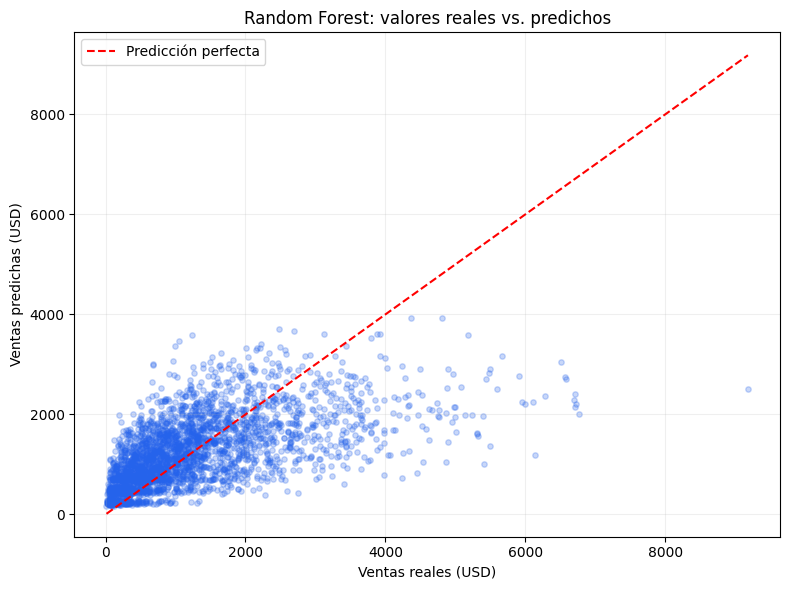

In [10]:
# Preparar resultados de validación
df_predicciones_rf = pd.DataFrame({
    "Valor real": np.asarray(y_reg_val),
    "Predicción": pred_rf_val
})

# Muestra reproducible para visualizar
muestra_rf = df_predicciones_rf.sample(
    n=min(3000, len(df_predicciones_rf)),
    random_state=42
)

plt.figure(figsize=(8, 6))

plt.scatter(
    muestra_rf["Valor real"],
    muestra_rf["Predicción"],
    alpha=0.25,
    s=15,
    color="#2563eb"
)

# Línea de predicción perfecta
limite_min = min(muestra_rf.min())
limite_max = max(muestra_rf.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    "r--",
    label="Predicción perfecta"
)

plt.xlabel("Ventas reales (USD)")
plt.ylabel("Ventas predichas (USD)")
plt.title("Random Forest: valores reales vs. predichos")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### 2.7. Optimización de hiperparámetros

Random Forest presenta una diferencia considerable entre su rendimiento en entrenamiento y validación, lo que sugiere posible sobreajuste.

Se realiza una búsqueda de hiperparámetros mediante validación cruzada de tres particiones, ajustando la profundidad máxima, el número mínimo de observaciones por hoja y la cantidad de variables consideradas en cada división.

El objetivo es mejorar la capacidad de generalización y reducir el RMSE.

In [11]:
# Definir hiperparámetros
parametros_rf = {
    "modelo__n_estimators": [100, 150],
    "modelo__max_depth": [6, 8, 10, 12],
    "modelo__min_samples_leaf": [10, 20, 40],
    "modelo__max_features": [0.6, 0.8, 1.0]
}

# Validación cruzada reproducible
cv_rf = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Búsqueda aleatoria
busqueda_rf = RandomizedSearchCV(
    estimator=modelo_rf,
    param_distributions=parametros_rf,
    n_iter=8,
    cv=cv_rf,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True
)

# Optimizar usando únicamente entrenamiento
busqueda_rf.fit(X_reg_train_f3, y_reg_train)

# Recuperar mejor modelo
modelo_rf_optimizado = busqueda_rf.best_estimator_

print("MEJORES HIPERPARÁMETROS")
print(busqueda_rf.best_params_)

print(
    "\nRMSE promedio en validación cruzada:",
    round(-busqueda_rf.best_score_, 4)
)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
MEJORES HIPERPARÁMETROS
{'modelo__n_estimators': 100, 'modelo__min_samples_leaf': 40, 'modelo__max_features': 0.8, 'modelo__max_depth': 6}

RMSE promedio en validación cruzada: 894.1796


### 2.8. Evaluación del modelo optimizado

Se evalúa Random Forest con los mejores hiperparámetros encontrados mediante validación cruzada.

Se compara su rendimiento con el modelo original y Ridge, considerando las métricas de entrenamiento y validación para determinar si disminuye el sobreajuste sin perjudicar significativamente la precisión predictiva.

In [12]:
# Predicciones del modelo optimizado
pred_rf_opt_train = modelo_rf_optimizado.predict(X_reg_train_f3)
pred_rf_opt_val = modelo_rf_optimizado.predict( X_reg_val_f3)

# Evaluar
resultados_rf_opt = pd.DataFrame({
    "Entrenamiento": evaluar_regresion_f3(
        y_reg_train, pred_rf_opt_train
    ),
    "Validación": evaluar_regresion_f3(
        y_reg_val, pred_rf_opt_val
    )
}).T

print("RESULTADOS - RANDOM FOREST OPTIMIZADO")
display(resultados_rf_opt.round(4))

# Comparar modelos
comparacion_optimizacion = pd.DataFrame({
    "Ridge": resultados_ridge.loc["Validación"],
    "Random Forest original": resultados_rf.loc["Validación"],
    "Random Forest optimizado": resultados_rf_opt.loc["Validación"]
}).T

print("\nCOMPARACIÓN EN VALIDACIÓN")
display(comparacion_optimizacion.round(4))

# Comparar diferencias entre entrenamiento y validación
diferencia_original = (
    resultados_rf.loc["Entrenamiento", "R2"]
    - resultados_rf.loc["Validación", "R2"]
)

diferencia_optimizado = (
    resultados_rf_opt.loc["Entrenamiento", "R2"]
    - resultados_rf_opt.loc["Validación", "R2"]
)

print("\nDIFERENCIA DE R²")
print(f"Random Forest original: {diferencia_original:.4f}")
print(f"Random Forest optimizado: {diferencia_optimizado:.4f}")

if diferencia_optimizado < diferencia_original:
    print("\nDisminuyó la diferencia de R² entre conjuntos.")
else:
    print("\nNo disminuyó la diferencia de R² entre conjuntos.")

RESULTADOS - RANDOM FOREST OPTIMIZADO


,MAE,RMSE,R2
Entrenamiento,613.296,889.518,0.384
Validación,609.484,880.403,0.372



COMPARACIÓN EN VALIDACIÓN


,MAE,RMSE,R2
Ridge,616.934,888.476,0.360
Random Forest original,614.812,887.951,0.361
Random Forest optimizado,609.484,880.403,0.372



DIFERENCIA DE R²
Random Forest original: 0.1726
Random Forest optimizado: 0.0115

Disminuyó la diferencia de R² entre conjuntos.


### 2.9. Conclusiones del modelado de regresión

Random Forest optimizado obtuvo en validación un **MAE de 609,48 USD**, un **RMSE de 880,40 USD** y un **R² de 0,372**. El RMSE bajó **13,66 USD (1,53 %)** frente a la regresión lineal de la Fase 2. La mejora sobre el modelo base fue modesta.

La diferencia de R² entre entrenamiento y validación pasó de **0,1726** en el Random Forest original a **0,0115** en el optimizado. Esto indica una menor brecha de desempeño entre esas dos particiones. Se selecciona el modelo optimizado para la evaluación final en prueba.



## 3. Modelado avanzado de clasificación

Se implementan modelos supervisados para identificar pedidos con riesgo de devolución.

Se utilizan las particiones estratificadas de la Fase 2, excluyendo las variables de fidelización asociadas a una posible fuga de información.

Debido al desbalance entre pedidos completados y devueltos, se priorizan Precision, Recall, F1-Score, AUC-ROC y Average Precision.


In [13]:
# Garantizar que no se incluyan variables sospechosas
columnas_excluir_clf = [ "loyalty_points_log","loyalty_points_redeemed"]

X_clf_train_f3 = X_clf_train.drop(columns=columnas_excluir_clf, errors="ignore").copy()
X_clf_val_f3 = X_clf_val.drop(columns=columnas_excluir_clf, errors="ignore").copy()
X_clf_test_f3 = X_clf_test.drop(columns=columnas_excluir_clf, errors="ignore").copy()

# Verificar consistencia
assert X_clf_train_f3.columns.equals(X_clf_val_f3.columns)
assert X_clf_train_f3.columns.equals(X_clf_test_f3.columns)
assert X_clf_train_f3.isna().sum().sum() == 0
assert set(np.unique(y_clf_train)) == {0, 1}

# Identificar tipos de variables
numericas_clf_f3 = X_clf_train_f3.select_dtypes(include=np.number).columns.tolist()

categoricas_clf_f3 = [
    col for col in X_clf_train_f3.columns
    if col not in numericas_clf_f3
]

print("DIMENSIONES")
print("Entrenamiento:", X_clf_train_f3.shape)
print("Validación:", X_clf_val_f3.shape)
print("Prueba:", X_clf_test_f3.shape)

print("\nDISTRIBUCIÓN DE CLASES")
for nombre, y in [
    ("Entrenamiento", y_clf_train),
    ("Validación", y_clf_val),
    ("Prueba", y_clf_test)
]:
    print(f"{nombre}: {np.mean(y) * 100:.2f}% devueltos")

print("\nVariables numéricas:", numericas_clf_f3)
print("Variables categóricas:", categoricas_clf_f3)


DIMENSIONES
Entrenamiento: (86114, 11)
Validación: (18453, 11)
Prueba: (18454, 11)

DISTRIBUCIÓN DE CLASES
Entrenamiento: 7.69% devueltos
Validación: 7.69% devueltos
Prueba: 7.69% devueltos

Variables numéricas: ['customer_age', 'quantity', 'order_month', 'is_weekend']
Variables categóricas: ['currency', 'customer_segment', 'sales_channel', 'customer_country', 'payment_method', 'shipping_method', 'marketing_channel']



### 3.1. Clasificación mediante Random Forest

Se implementa Random Forest Classifier para identificar posibles devoluciones a partir de características comerciales, demográficas y temporales.

Se utiliza `class_weight="balanced_subsample"` para compensar el desbalance de clases durante el entrenamiento.

El modelo se integra con One-Hot Encoding dentro de un Pipeline, ajustado exclusivamente sobre los datos de entrenamiento.


In [14]:
# Preprocesamiento
preprocesador_rf_clf = ColumnTransformer([
    ("numericas", "passthrough", numericas_clf_f3),
    ("categoricas",
     OneHotEncoder(handle_unknown="ignore"),
     categoricas_clf_f3)
])

# Pipeline de clasificación
modelo_rf_clf = Pipeline([
    ("preprocesamiento", preprocesador_rf_clf),
    ("modelo", RandomForestClassifier(
        n_estimators=150,
        max_depth=10,
        min_samples_leaf=20,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

# Entrenamiento
modelo_rf_clf.fit(X_clf_train_f3, y_clf_train)

# Predicciones en entrenamiento
pred_rf_clf_train = modelo_rf_clf.predict(X_clf_train_f3)

proba_rf_clf_train = modelo_rf_clf.predict_proba(
    X_clf_train_f3
)[:, 1]

# Predicciones en validación
pred_rf_clf_val = modelo_rf_clf.predict(X_clf_val_f3)

proba_rf_clf_val = modelo_rf_clf.predict_proba(
    X_clf_val_f3
)[:, 1]

print("RANDOM FOREST CLASSIFIER ENTRENADO CORRECTAMENTE")


RANDOM FOREST CLASSIFIER ENTRENADO CORRECTAMENTE



### 3.2. Evaluación de Random Forest Classifier

Se evalúa el modelo mediante Accuracy, Precision, Recall, F1-Score, AUC-ROC y Average Precision.

También se examina la matriz de confusión para identificar falsos positivos y falsos negativos, considerando que detectar devoluciones es el principal objetivo de clasificación.


RESULTADOS - RANDOM FOREST CLASSIFIER


,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Average Precision
Entrenamiento,0.647,0.138,0.682,0.229,0.725,0.201
Validación,0.612,0.086,0.423,0.144,0.552,0.090


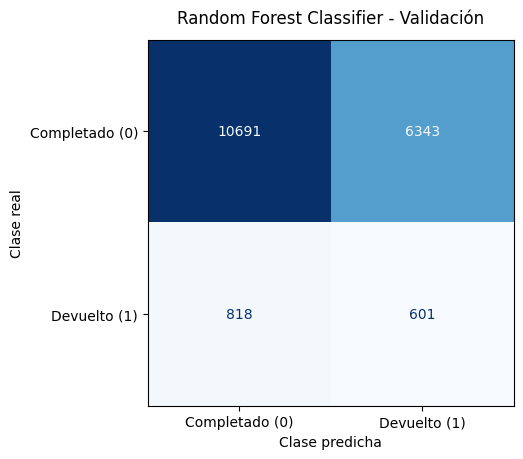


REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

  Completado       0.93      0.63      0.75     17034
    Devuelto       0.09      0.42      0.14      1419

    accuracy                           0.61     18453
   macro avg       0.51      0.53      0.45     18453
weighted avg       0.86      0.61      0.70     18453



In [15]:

# Función reutilizable de evaluación
def evaluar_clasificacion_f3(y_real, pred, proba):
    return {
        "Accuracy": accuracy_score(y_real, pred),
        "Precision": precision_score(
            y_real, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_real, pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_real, pred, zero_division=0
        ),
        "AUC-ROC": roc_auc_score(y_real, proba),
        "Average Precision": average_precision_score(
            y_real, proba
        )
    }

# Evaluación
resultados_rf_clf = pd.DataFrame({
    "Entrenamiento": evaluar_clasificacion_f3(
        y_clf_train, pred_rf_clf_train, proba_rf_clf_train
    ),
    "Validación": evaluar_clasificacion_f3(
        y_clf_val, pred_rf_clf_val, proba_rf_clf_val
    )
}).T

print("RESULTADOS - RANDOM FOREST CLASSIFIER")
display(resultados_rf_clf.round(4))

# Matriz de confusión
matriz_rf_clf = confusion_matrix(
    y_clf_val, pred_rf_clf_val, labels=[0, 1]
)

graficar_matriz_confusion(
    matriz_rf_clf,
    "Random Forest Classifier - Validación"
)

# Reporte por clase
print("\nREPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_clf_val,
    pred_rf_clf_val,
    target_names=["Completado", "Devuelto"],
    zero_division=0
))


COMPARACIÓN DE MODELOS DE CLASIFICACIÓN


,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Average Precision
DummyClassifier,0.923,0.000,0.000,0.000,0.500,0.077
Regresión logística corregida,0.502,0.086,0.573,0.150,0.556,0.088
Random Forest,0.612,0.086,0.423,0.144,0.552,0.090


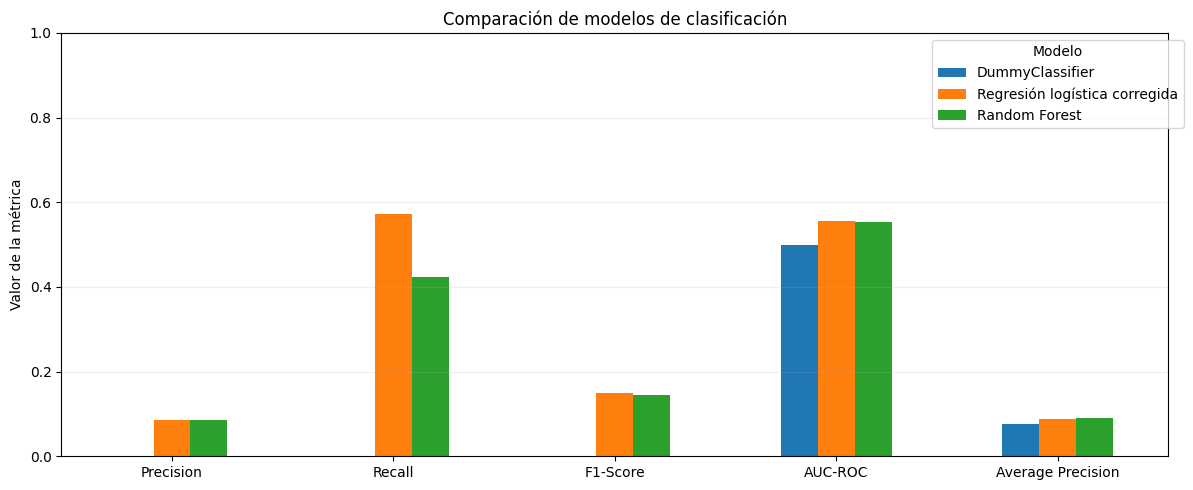

In [16]:
# Comparar clasificación sin fuga de información
comparacion_clasificacion_f3 = pd.concat([
    baseline_clf,
    resultados_rf_clf.loc[
        ["Validación"]].rename(index={"Validación": "Random Forest"})
])

print("COMPARACIÓN DE MODELOS DE CLASIFICACIÓN")
display(comparacion_clasificacion_f3.round(4))

# Comparación gráfica de métricas relevantes
metricas_clf = ["Precision","Recall",
    "F1-Score","AUC-ROC","Average Precision"]

ax = comparacion_clasificacion_f3[metricas_clf].T.plot(
    kind="bar", figsize=(12, 5), rot=0)

ax.set_title("Comparación de modelos de clasificación")
ax.set_ylabel("Valor de la métrica")
ax.set_ylim(0, 1)
ax.legend(title="Modelo", bbox_to_anchor=(1.02, 1))
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()



### 3.3. Análisis de Random Forest Classifier

Random Forest alcanzó un F1-Score de 0,144 y AUC-ROC de 0,552 en validación, sin superar el rendimiento de la regresión logística corregida.

Se identificaron señales de sobreajuste, especialmente en AUC-ROC, que disminuyó de 0,725 en entrenamiento a 0,552 en validación.

Debido al desbalance de clases y la limitada capacidad discriminativa, se evaluará un segundo algoritmo antes de seleccionar el modelo definitivo.



### 3.4. Clasificación mediante Support Vector Machine (SVM)

Se implementa una máquina de soporte vectorial lineal (LinearSVC) para clasificar pedidos según su riesgo de devolución.

El algoritmo busca un hiperplano que permita separar ambas clases maximizando el margen de separación.

Se utiliza escalamiento de variables numéricas, One-Hot Encoding para las categóricas y balanceo de clases. El preprocesamiento se ajusta únicamente con los datos de entrenamiento.


In [17]:
# Preprocesamiento para SVM
preprocesador_svm = ColumnTransformer([
    ("numericas",
     StandardScaler(),
     numericas_clf_f3),

    ("categoricas",
     OneHotEncoder(handle_unknown="ignore"),
     categoricas_clf_f3)
])

# Crear pipeline de SVM lineal
modelo_svm = Pipeline([
    ("preprocesamiento", preprocesador_svm),
    ("modelo", LinearSVC(
        C=0.1,
        class_weight="balanced",
        max_iter=10000,
        tol=1e-3,
        dual=False,
        random_state=42
    ))
])

# Entrenar solamente con entrenamiento
modelo_svm.fit(X_clf_train_f3, y_clf_train)

# Predicciones de entrenamiento
pred_svm_train = modelo_svm.predict(X_clf_train_f3)

# Puntuaciones para AUC-ROC y Average Precision
scores_svm_train = modelo_svm.decision_function(
    X_clf_train_f3
)

# Predicciones de validación
pred_svm_val = modelo_svm.predict(X_clf_val_f3)

scores_svm_val = modelo_svm.decision_function(
    X_clf_val_f3
)

print("SVM LINEAL ENTRENADO CORRECTAMENTE")


SVM LINEAL ENTRENADO CORRECTAMENTE



### 3.5. Evaluación del modelo SVM

Se evalúa SVM mediante Accuracy, Precision, Recall, F1-Score, AUC-ROC y Average Precision.

Se analizan las diferencias entre entrenamiento y validación para identificar posibles señales de sobreajuste.

Adicionalmente, se representa gráficamente la matriz de confusión para evaluar la identificación de pedidos devueltos y completados.


RESULTADOS - SVM


,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Average Precision
Entrenamiento,0.500,0.089,0.594,0.155,0.562,0.093
Validación,0.500,0.086,0.570,0.149,0.556,0.088


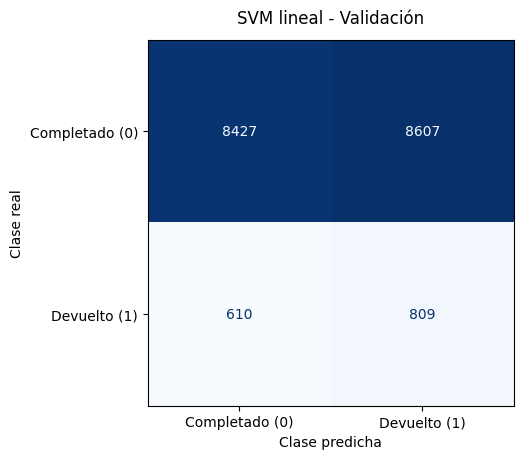


REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

  Completado       0.93      0.49      0.65     17034
    Devuelto       0.09      0.57      0.15      1419

    accuracy                           0.50     18453
   macro avg       0.51      0.53      0.40     18453
weighted avg       0.87      0.50      0.61     18453



In [18]:
# Evaluación del modelo
resultados_svm = pd.DataFrame({
    "Entrenamiento": evaluar_clasificacion_f3(
        y_clf_train,
        pred_svm_train,
        scores_svm_train
    ),
    "Validación": evaluar_clasificacion_f3(
        y_clf_val,
        pred_svm_val,
        scores_svm_val
    )
}).T

print("RESULTADOS - SVM")
display(resultados_svm.round(4))

# Matriz de confusión
matriz_svm = confusion_matrix( y_clf_val, pred_svm_val, labels=[0, 1])

graficar_matriz_confusion(matriz_svm, "SVM lineal - Validación")

# Reporte completo
print("\nREPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_clf_val,
    pred_svm_val,
    target_names=["Completado", "Devuelto"],
    zero_division=0
))



### 3.6. Comparación de modelos de clasificación

Se comparan los modelos DummyClassifier, regresión logística corregida, Random Forest y SVM lineal.

Debido al desbalance entre clases, se priorizan F1-Score, AUC-ROC y Average Precision sobre Accuracy.

Los resultados permiten identificar el clasificador más prometedor para la posterior optimización de hiperparámetros.


COMPARACIÓN DE CLASIFICADORES


,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Average Precision
DummyClassifier,0.923,0.000,0.000,0.000,0.500,0.077
Regresión logística corregida,0.502,0.086,0.573,0.150,0.556,0.088
Random Forest,0.612,0.086,0.423,0.144,0.552,0.090
SVM lineal,0.500,0.086,0.570,0.149,0.556,0.088


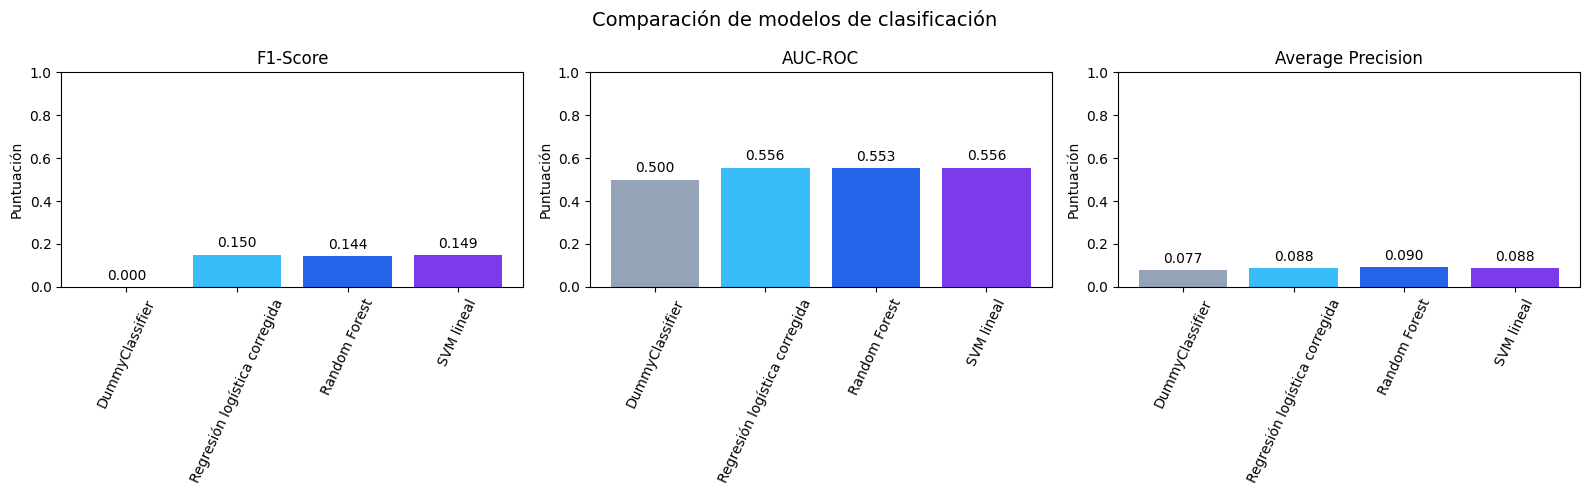

Mejor modelo por F1-Score: Regresión logística corregida
Mejor modelo por AUC-ROC: Regresión logística corregida
Mejor modelo por Average Precision: Random Forest


In [19]:
# Incorporar SVM a la comparación
comparacion_clasificacion_f3.loc["SVM lineal"] = ( resultados_svm.loc["Validación"])

print("COMPARACIÓN DE CLASIFICADORES")
display(comparacion_clasificacion_f3.round(4))

# Comparar las tres métricas más relevantes
metricas_evaluacion = [ "F1-Score", "AUC-ROC", "Average Precision"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metrica in zip(axes, metricas_evaluacion):
    valores = comparacion_clasificacion_f3[metrica]

    barras = ax.bar(
        valores.index,
        valores.values,
        color=["#94a3b8", "#38bdf8",
               "#2563eb", "#7c3aed"]
    )

    ax.set_title(metrica)
    ax.set_ylabel("Puntuación")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=65)
    ax.bar_label(barras, fmt="%.3f", padding=3)

plt.suptitle(
    "Comparación de modelos de clasificación",
    fontsize=14
)
plt.tight_layout()
plt.show()

# Identificar los mejores modelos
for metrica in metricas_evaluacion:
    mejor = comparacion_clasificacion_f3[metrica].idxmax()

    print(f"Mejor modelo por {metrica}: {mejor}")



### 3.7. Curvas Precision-Recall

Se comparan las curvas Precision-Recall de Random Forest y SVM para analizar su comportamiento frente al desbalance de clases.

Estas curvas permiten visualizar el compromiso entre detectar una mayor proporción de devoluciones y reducir las falsas alarmas.

Se utiliza como referencia la proporción real de devoluciones en validación.


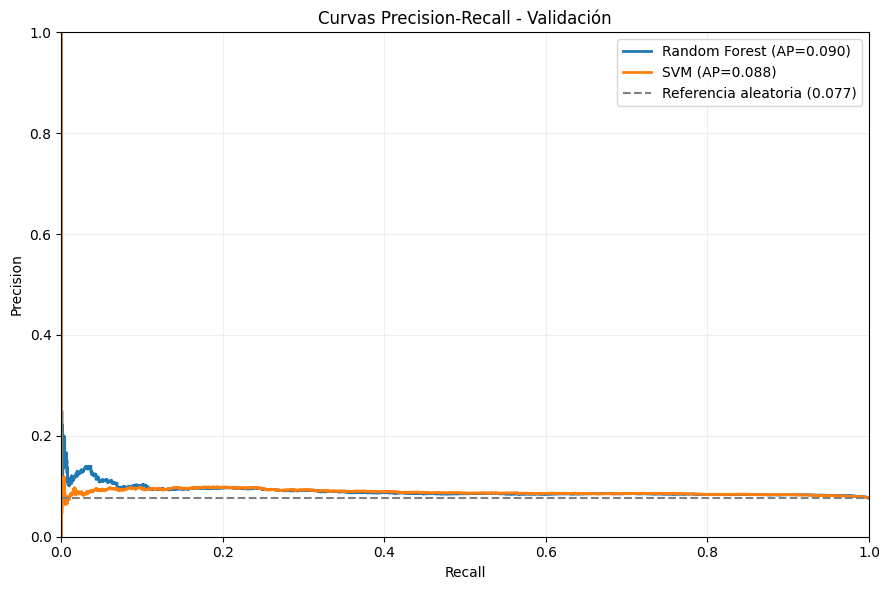

In [20]:
# Curva de Random Forest
precision_rf, recall_rf, _ = precision_recall_curve(y_clf_val,proba_rf_clf_val)

# Curva de SVM
precision_svm, recall_svm, _ = precision_recall_curve(y_clf_val, scores_svm_val)

# Referencia: proporción real de devoluciones
prevalencia = np.mean(y_clf_val)

plt.figure(figsize=(9, 6))

plt.plot(recall_rf,precision_rf,
    label=("Random Forest " f"(AP={resultados_rf_clf.loc['Validación', 'Average Precision']:.3f})"),
    linewidth=2)

plt.plot(recall_svm, precision_svm,
    label=("SVM " f"(AP={resultados_svm.loc['Validación', 'Average Precision']:.3f})"),
    linewidth=2)

plt.axhline(
    prevalencia,
    color="gray",
    linestyle="--",
    label=f"Referencia aleatoria ({prevalencia:.3f})")

plt.title("Curvas Precision-Recall - Validación")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()



### 3.8. Optimización de Random Forest Classifier

Random Forest presentó señales de sobreajuste y un rendimiento limitado en la detección de devoluciones.

Se realiza una búsqueda de hiperparámetros mediante validación cruzada estratificada de tres particiones.

La optimización utiliza Average Precision como criterio principal, considerando el desbalance de clases. Se ajustan la profundidad de los árboles, el número mínimo de observaciones por hoja y la cantidad de variables evaluadas en cada división.


In [21]:
# Configuración de hiperparámetros
parametros_rf_clf = {
    "modelo__n_estimators": [100, 150],
    "modelo__max_depth": [4, 6, 8],
    "modelo__min_samples_leaf": [30, 60, 100],
    "modelo__max_features": ["sqrt", 0.5, 0.8]
}

# Validación cruzada estratificada
cv_clf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Búsqueda de hiperparámetros
busqueda_rf_clf = RandomizedSearchCV(
    estimator=modelo_rf_clf, param_distributions=parametros_rf_clf, n_iter=6,
    scoring="average_precision", cv=cv_clf,random_state=42, n_jobs=1, verbose=1, refit=True)

# Entrenar únicamente con datos de entrenamiento
busqueda_rf_clf.fit(X_clf_train_f3, y_clf_train)

# Recuperar mejor modelo
modelo_rf_clf_opt = busqueda_rf_clf.best_estimator_

print("MEJORES HIPERPARÁMETROS")
print(busqueda_rf_clf.best_params_)

print("\nAverage Precision promedio en CV:", round(busqueda_rf_clf.best_score_, 4))


Fitting 3 folds for each of 6 candidates, totalling 18 fits
MEJORES HIPERPARÁMETROS
{'modelo__n_estimators': 100, 'modelo__min_samples_leaf': 30, 'modelo__max_features': 0.8, 'modelo__max_depth': 4}

Average Precision promedio en CV: 0.1004



### 3.9. Evaluación del Random Forest optimizado

Se evalúa el modelo optimizado sobre entrenamiento y validación, utilizando las métricas definidas previamente.

Se compara su rendimiento con Random Forest original y SVM lineal para determinar si la optimización mejora la generalización y la identificación de devoluciones.


In [22]:
# Predicciones en entrenamiento
pred_rf_clf_opt_train = modelo_rf_clf_opt.predict( X_clf_train_f3)

proba_rf_clf_opt_train = modelo_rf_clf_opt.predict_proba( X_clf_train_f3)[:, 1]

# Predicciones en validación
pred_rf_clf_opt_val = modelo_rf_clf_opt.predict(X_clf_val_f3)

proba_rf_clf_opt_val = modelo_rf_clf_opt.predict_proba( X_clf_val_f3)[:, 1]

# Evaluación
resultados_rf_clf_opt = pd.DataFrame({
    "Entrenamiento": evaluar_clasificacion_f3(
        y_clf_train,
        pred_rf_clf_opt_train,
        proba_rf_clf_opt_train
    ),
    "Validación": evaluar_clasificacion_f3(
        y_clf_val,
        pred_rf_clf_opt_val,
        proba_rf_clf_opt_val
    )
}).T

print("RESULTADOS - RANDOM FOREST OPTIMIZADO")
display(resultados_rf_clf_opt.round(4))

# Comparación de los modelos
comparacion_opt_clf = pd.DataFrame({
    "Random Forest original": resultados_rf_clf.loc["Validación"],
    "Random Forest optimizado": resultados_rf_clf_opt.loc["Validación"],
    "SVM lineal": resultados_svm.loc["Validación"]
}).T

print("\nCOMPARACIÓN EN VALIDACIÓN")
display(comparacion_opt_clf.round(4))

# Analizar sobreajuste mediante AUC-ROC
diferencia_auc_original = (
    resultados_rf_clf.loc["Entrenamiento", "AUC-ROC"]
    - resultados_rf_clf.loc["Validación", "AUC-ROC"]
)

diferencia_auc_opt = (
    resultados_rf_clf_opt.loc["Entrenamiento", "AUC-ROC"]
    - resultados_rf_clf_opt.loc["Validación", "AUC-ROC"]
)

print("\nDIFERENCIA DE AUC-ROC")
print(f"RF original: {diferencia_auc_original:.4f}")
print(f"RF optimizado: {diferencia_auc_opt:.4f}")


RESULTADOS - RANDOM FOREST OPTIMIZADO


,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Average Precision
Entrenamiento,0.449,0.091,0.682,0.160,0.588,0.107
Validación,0.443,0.085,0.642,0.150,0.557,0.091



COMPARACIÓN EN VALIDACIÓN


,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Average Precision
Random Forest original,0.612,0.086,0.423,0.144,0.552,0.090
Random Forest optimizado,0.443,0.085,0.642,0.150,0.557,0.091
SVM lineal,0.500,0.086,0.570,0.149,0.556,0.088



DIFERENCIA DE AUC-ROC
RF original: 0.1726
RF optimizado: 0.0308


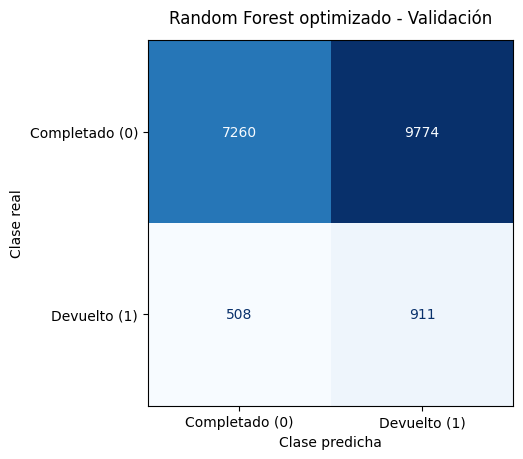


REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

  Completado       0.93      0.43      0.59     17034
    Devuelto       0.09      0.64      0.15      1419

    accuracy                           0.44     18453
   macro avg       0.51      0.53      0.37     18453
weighted avg       0.87      0.44      0.55     18453



In [23]:
# Matriz de confusión del modelo optimizado
matriz_rf_clf_opt = confusion_matrix(
    y_clf_val,
    pred_rf_clf_opt_val,
    labels=[0, 1]
)

graficar_matriz_confusion( matriz_rf_clf_opt, "Random Forest optimizado - Validación")

print("\nREPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_clf_val,
    pred_rf_clf_opt_val,
    target_names=["Completado", "Devuelto"],
    zero_division=0
))


### 3.10. Optimización del umbral de clasificación

Se prueban distintos umbrales sobre las puntuaciones del Random Forest optimizado en validación. Se selecciona el que maximiza F1 para combinar precisión y sensibilidad en una sola métrica.

Un umbral más bajo puede detectar más devoluciones y generar más falsas alarmas. Por eso, además del F1, se revisan la precisión, la sensibilidad y los conteos de la matriz de confusión. El umbral elegido en validación se aplica en prueba.

In [24]:

# Curva Precision-Recall
precision, recall, umbrales = precision_recall_curve(
    y_clf_val,
    proba_rf_clf_opt_val
)

# Calcular F1 para cada umbral
f1_por_umbral = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

# Seleccionar umbral con mejor F1
indice_optimo = np.argmax(f1_por_umbral)

umbral_optimo_rf = float(umbrales[indice_optimo])

print("OPTIMIZACIÓN DEL UMBRAL")
print(f"Umbral original: 0.5000")
print(f"Umbral seleccionado: {umbral_optimo_rf:.4f}")
print(f"Mejor F1 en validación: {f1_por_umbral[indice_optimo]:.4f}")
print(f"Precision: {precision[indice_optimo]:.4f}")
print(f"Recall: {recall[indice_optimo]:.4f}")


OPTIMIZACIÓN DEL UMBRAL
Umbral original: 0.5000
Umbral seleccionado: 0.4911
Mejor F1 en validación: 0.1542
Precision: 0.0855
Recall: 0.7865



### 3.11. Comparación de umbrales

Se compara el rendimiento del Random Forest optimizado utilizando el umbral predeterminado de 0,5 y el umbral seleccionado mediante F1-Score.

El análisis permite determinar si el ajuste mejora el equilibrio entre Precision y Recall. Las métricas AUC-ROC y Average Precision permanecen constantes porque utilizan las puntuaciones del modelo y no las etiquetas obtenidas con un umbral específico.


COMPARACIÓN DE UMBRALES


,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Average Precision
Umbral 0.5,0.443,0.085,0.642,0.150,0.557,0.091
Umbral optimizado,0.337,0.086,0.786,0.154,0.557,0.091


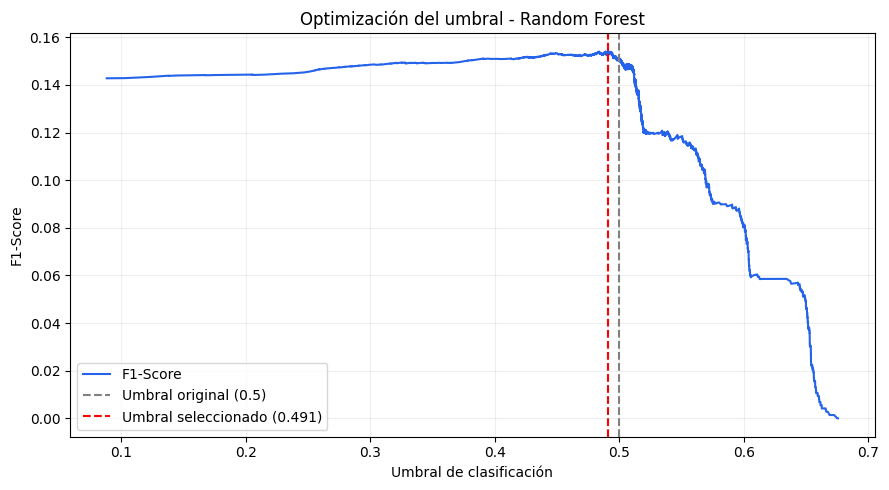

In [25]:

# Nuevas predicciones con el umbral seleccionado
pred_rf_umbral = (
    proba_rf_clf_opt_val >= umbral_optimo_rf
).astype(int)

# Evaluar umbrales
resultados_umbral = pd.DataFrame({
    "Umbral 0.5": evaluar_clasificacion_f3(
        y_clf_val,
        pred_rf_clf_opt_val,
        proba_rf_clf_opt_val
    ),
    "Umbral optimizado": evaluar_clasificacion_f3(
        y_clf_val,
        pred_rf_umbral,
        proba_rf_clf_opt_val
    )
}).T

print("COMPARACIÓN DE UMBRALES")
display(resultados_umbral.round(4))

# Graficar comportamiento de F1
plt.figure(figsize=(9, 5))

plt.plot(
    umbrales,
    f1_por_umbral,
    color="#2563eb",
    label="F1-Score"
)

plt.axvline(
    0.5,
    color="gray",
    linestyle="--",
    label="Umbral original (0.5)"
)

plt.axvline(
    umbral_optimo_rf,
    color="red",
    linestyle="--",
    label=f"Umbral seleccionado ({umbral_optimo_rf:.3f})"
)

plt.xlabel("Umbral de clasificación")
plt.ylabel("F1-Score")
plt.title("Optimización del umbral - Random Forest")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


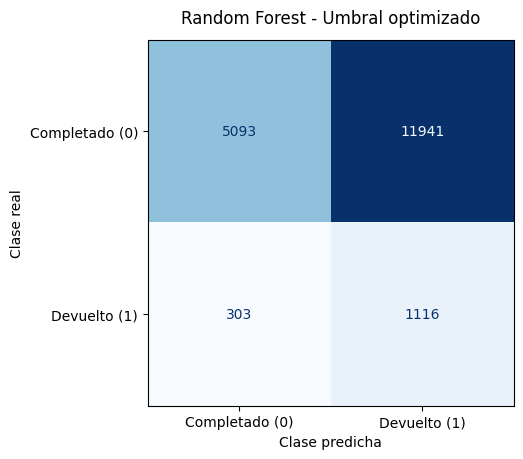


REPORTE CON UMBRAL OPTIMIZADO
              precision    recall  f1-score   support

  Completado       0.94      0.30      0.45     17034
    Devuelto       0.09      0.79      0.15      1419

    accuracy                           0.34     18453
   macro avg       0.51      0.54      0.30     18453
weighted avg       0.88      0.34      0.43     18453


Umbral candidato guardado: 0.4911


In [26]:

# Matriz de confusión con umbral seleccionado
matriz_rf_umbral = confusion_matrix(
    y_clf_val,
    pred_rf_umbral,
    labels=[0, 1]
)

graficar_matriz_confusion(
    matriz_rf_umbral,
    "Random Forest - Umbral optimizado"
)

# Reporte de clasificación
print("\nREPORTE CON UMBRAL OPTIMIZADO")
print(classification_report(
    y_clf_val,
    pred_rf_umbral,
    target_names=["Completado", "Devuelto"],
    zero_division=0
))

# Guardar configuración candidata
modelo_clasificacion_candidato = modelo_rf_clf_opt
umbral_clasificacion_candidato = umbral_optimo_rf

print(
    f"\nUmbral candidato guardado: "
    f"{umbral_clasificacion_candidato:.4f}"
)


### 3.12. Conclusiones del modelado de clasificación

En validación, Random Forest optimizado obtuvo un **AUC-ROC de 0,557** y una **Average Precision de 0,091**. El `DummyClassifier` obtuvo una Average Precision de **0,077**, por lo que la mejora sobre la referencia fue pequeña.

Con el umbral de **0,4911**, la sensibilidad subió del **64,2 % al 78,6 %** y el F1 pasó de **0,150 a 0,154**. La precisión quedó alrededor del **8,6 %**, equivalente a unas nueve devoluciones reales por cada cien alertas. El modelo y ese umbral pasan a la evaluación final con un alcance exploratorio.


## 4. Segmentación mediante aprendizaje no supervisado

Se aplican técnicas de clustering para identificar grupos de pedidos con características similares.

El análisis se realiza sobre transacciones en USD, evitando comparar directamente ventas expresadas en diferentes monedas.

Se implementarán K-Means y DBSCAN, evaluando la estructura de los grupos mediante el método del codo, el coeficiente de silueta y la interpretación de sus perfiles comerciales.



### 4.1. Selección y transformación de variables

Se seleccionan tres características cuantitativas: edad del cliente, cantidad de productos y ventas netas.

Se aplica una transformación logarítmica a `quantity` y `net_sales` para reducir la influencia de los valores extremos, seguida de estandarización para equilibrar las escalas.

Las variables temporales se conservarán para interpretar los grupos, pero no se utilizarán inicialmente para calcular las distancias.


In [27]:

# Recuperar datos exportados desde la Fase 2
df_segmentos = df_clustering.copy()

# Variables seleccionadas
variables_cluster = [
    "customer_age",
    "quantity",
    "net_sales"
]

# Verificar disponibilidad y calidad
assert all(
    col in df_segmentos.columns
    for col in variables_cluster
)

assert df_segmentos[variables_cluster].notna().all().all()
assert (df_segmentos["quantity"] > 0).all()
assert (df_segmentos["net_sales"] >= 0).all()

# Transformaciones logarítmicas
df_segmentos["log_quantity"] = np.log1p(
    df_segmentos["quantity"]
)

df_segmentos["log_net_sales"] = np.log1p(
    df_segmentos["net_sales"]
)

# Características utilizadas por K-Means
variables_kmeans = [
    "customer_age",
    "log_quantity",
    "log_net_sales"
]

X_cluster_original = df_segmentos[
    variables_kmeans
].copy()

# Estandarización
escalador_cluster = StandardScaler()

X_cluster = escalador_cluster.fit_transform(
    X_cluster_original
)

print("PREPARACIÓN PARA CLUSTERING")
print("Registros:", X_cluster.shape[0])
print("Variables:", X_cluster.shape[1])

print("\nVARIABLES UTILIZADAS")
print(variables_kmeans)

print("\nESTADÍSTICAS ORIGINALES")
display(
    df_segmentos[variables_cluster]
    .describe()
    .round(2)
)

print("\nVALORES FALTANTES:",
      np.isnan(X_cluster).sum())


PREPARACIÓN PARA CLUSTERING
Registros: 82600
Variables: 3

VARIABLES UTILIZADAS
['customer_age', 'log_quantity', 'log_net_sales']

ESTADÍSTICAS ORIGINALES


,customer_age,quantity,net_sales
count,"82,600.000","82,600.000","82,600.000"
mean,45.830,5.610,"1,237.650"
std,16.480,3.370,"1,128.660"
min,18.000,1.000,5.800
25%,31.000,3.000,432.370
50%,46.000,5.000,915.620
75%,60.000,8.000,"1,684.540"
max,74.000,24.000,"16,218.000"



VALORES FALTANTES: 0



### 4.2. Selección del número óptimo de clústeres

Se evalúan diferentes valores de K, desde 2 hasta 8, mediante el método del codo y el coeficiente de silueta.

El método del codo permite analizar la reducción de la inercia, mientras que la silueta evalúa la cohesión y separación de los grupos.

Para reducir el costo computacional, la silueta se calcula sobre una muestra reproducible de 2.000 observaciones, utilizando los clústeres obtenidos con el conjunto completo.


In [28]:
# Valores de K que se evaluarán
valores_k = range(2, 9)
resultados_k = []

# Muestra fija para calcular silueta
rng = np.random.default_rng(42)

indices_muestra = rng.choice(X_cluster.shape[0],
    size=min(2000, X_cluster.shape[0]),replace=False)

X_cluster_muestra = X_cluster[indices_muestra]

for k in valores_k:

    # Entrenar K-Means con todos los registros
    modelo_k = KMeans( n_clusters=k,
        random_state=42, n_init=10)

    modelo_k.fit(X_cluster)

    # Asignar grupos a la muestra
    etiquetas_muestra = modelo_k.predict(X_cluster_muestra)

    # Calcular silueta aproximada
    silueta = silhouette_score( X_cluster_muestra, etiquetas_muestra)

    resultados_k.append({
        "K": k,
        "Inercia": modelo_k.inertia_,
        "Silueta": silueta
    })

# Resultados
resultados_k = pd.DataFrame(resultados_k)

print("EVALUACIÓN DEL NÚMERO DE CLÚSTERES")
display(resultados_k.round(4))

# Mejor K según silueta
mejor_k_silueta = int(
    resultados_k.loc[
        resultados_k["Silueta"].idxmax(), "K"
    ])

print(f"\nMejor K según silueta: {mejor_k_silueta}")


EVALUACIÓN DEL NÚMERO DE CLÚSTERES


,K,Inercia,Silueta
0,2,"154,092.491",0.329
1,3,"111,226.929",0.328
2,4,"92,125.255",0.311
3,5,"76,683.362",0.297
4,6,"68,270.037",0.283
5,7,"62,918.677",0.265
6,8,"57,922.624",0.251



Mejor K según silueta: 2



### 4.3. Análisis gráfico del número de clústeres

Se representan la inercia y el coeficiente de silueta para los diferentes valores de K.

La selección final considerará tanto la calidad de separación de los grupos como su interpretabilidad comercial, evitando elegir un número de clústeres únicamente por una métrica.


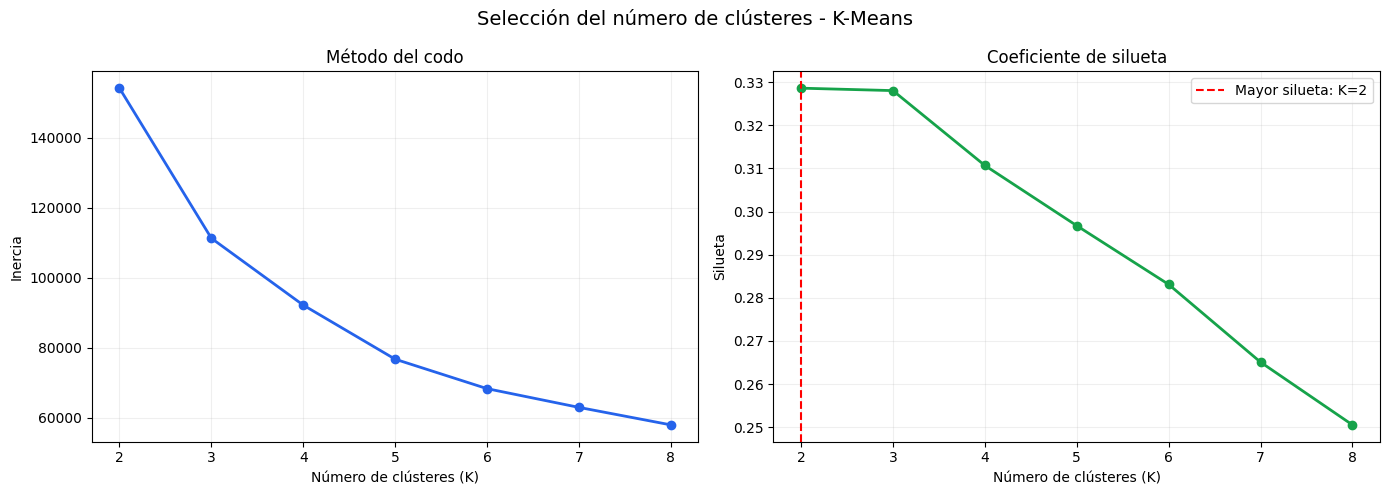

In [29]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Método del codo
axes[0].plot(
    resultados_k["K"],
    resultados_k["Inercia"],
    marker="o",
    color="#2563eb",
    linewidth=2
)

axes[0].set_title("Método del codo")
axes[0].set_xlabel("Número de clústeres (K)")
axes[0].set_ylabel("Inercia")
axes[0].grid(alpha=0.2)

# Coeficiente de silueta
axes[1].plot(
    resultados_k["K"],
    resultados_k["Silueta"],
    marker="o",
    color="#16a34a",
    linewidth=2
)

# Resaltar mejor K según silueta
axes[1].axvline(
    mejor_k_silueta,
    linestyle="--",
    color="red",
    label=f"Mayor silueta: K={mejor_k_silueta}"
)

axes[1].set_title("Coeficiente de silueta")
axes[1].set_xlabel("Número de clústeres (K)")
axes[1].set_ylabel("Silueta")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.suptitle(
    "Selección del número de clústeres - K-Means",
    fontsize=14
)

plt.tight_layout()
plt.show()



### 4.4. Identificación del codo mediante máxima distancia

Debido a que la curva de inercia no presenta un codo visualmente definido, se complementa el análisis mediante el método de máxima distancia a la recta.

Este procedimiento normaliza los valores de K e inercia y selecciona el punto con mayor distancia perpendicular a la línea que conecta los extremos de la curva.

La estimación se contrasta con el coeficiente de silueta y la reducción porcentual de inercia para seleccionar un número de clústeres justificable.


In [30]:

# Recuperar resultados del análisis anterior
valores_k = resultados_k["K"].to_numpy()
inercias = resultados_k["Inercia"].to_numpy()
siluetas = resultados_k["Silueta"].to_numpy()

# Normalizar K e inercia entre 0 y 1
k_norm = ((valores_k - valores_k.min()) / (valores_k.max() - valores_k.min()))

inercia_norm = ((inercias - inercias.min()) / (inercias.max() - inercias.min()))

# Recta entre los extremos normalizados
recta_referencia = 1 - k_norm

# Distancia perpendicular a la recta
distancias = np.abs(
    inercia_norm - recta_referencia
) / np.sqrt(2)

# Identificar el punto de mayor distancia
indice_codo = np.argmax(distancias)
k_codo = int(valores_k[indice_codo])

# Calcular reducción porcentual de inercia
reduccion_inercia = np.full(len(inercias), np.nan)
reduccion_inercia[1:] = ((inercias[:-1] - inercias[1:]) / inercias[:-1]) * 100

# Tabla de resultados
analisis_k = resultados_k.copy()

analisis_k["Distancia al codo"] = distancias
analisis_k["Reducción inercia (%)"] = reduccion_inercia

print("ANÁLISIS COMPLEMENTARIO DEL CODO")
display(analisis_k.round(4))

print(f"\nK estimado por máxima distancia: {k_codo}")
print(f"K con mayor silueta: {mejor_k_silueta}")


ANÁLISIS COMPLEMENTARIO DEL CODO


,K,Inercia,Silueta,Distancia al codo,Reducción inercia (%)
0,2,"154,092.491",0.329,0.000,NaN
1,3,"111,226.929",0.328,0.197,27.818
2,4,"92,125.255",0.311,0.220,17.174
3,5,"76,683.362",0.297,0.216,16.762
4,6,"68,270.037",0.283,0.160,10.972
5,7,"62,918.677",0.265,0.081,7.838
6,8,"57,922.624",0.251,0.000,7.941



K estimado por máxima distancia: 4
K con mayor silueta: 2


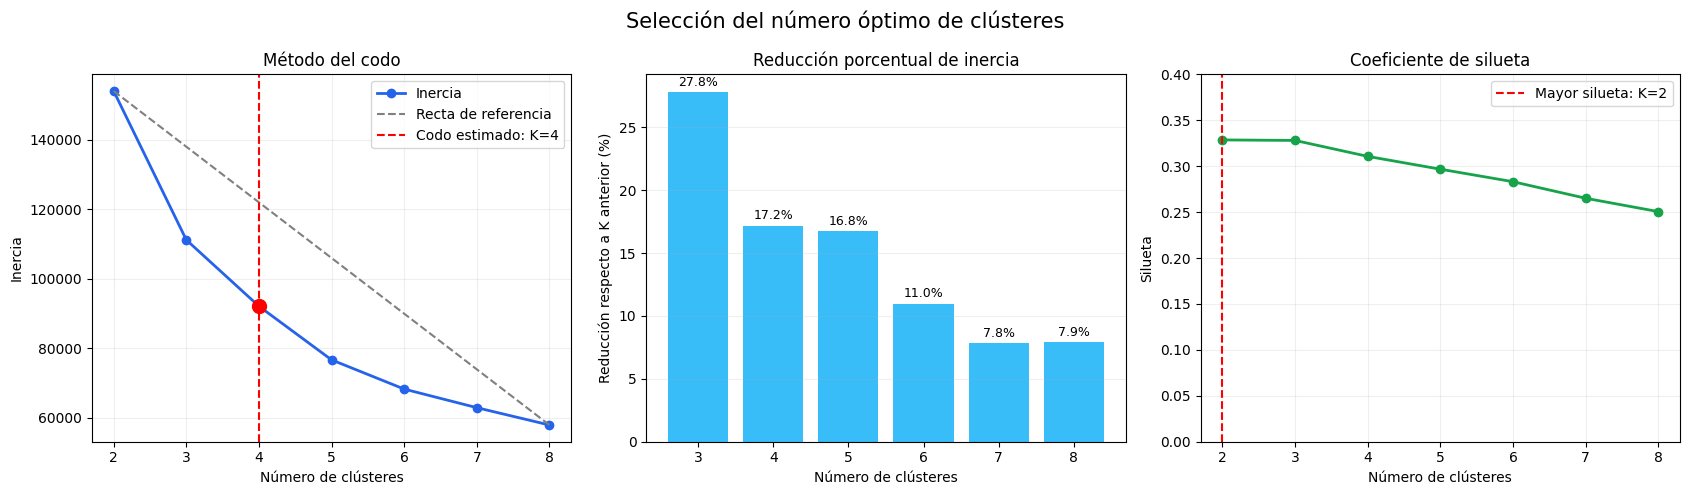

In [31]:

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 1. Codo mediante máxima distancia
axes[0].plot(
    valores_k, inercias,
    marker="o", linewidth=2,
    color="#2563eb",
    label="Inercia"
)

# Recta de referencia en escala original
axes[0].plot(
    [valores_k[0], valores_k[-1]],
    [inercias[0], inercias[-1]],
    "--", color="gray",
    label="Recta de referencia"
)

axes[0].axvline(
    k_codo,
    color="red", linestyle="--",
    label=f"Codo estimado: K={k_codo}"
)

axes[0].scatter(
    k_codo, inercias[indice_codo],
    color="red", s=100, zorder=5
)

axes[0].set_title("Método del codo")
axes[0].set_xlabel("Número de clústeres")
axes[0].set_ylabel("Inercia")
axes[0].legend()
axes[0].grid(alpha=0.2)

# 2. Reducción porcentual de inercia
axes[1].bar(
    valores_k[1:],
    reduccion_inercia[1:],
    color="#38bdf8"
)

for k, valor in zip(
    valores_k[1:], reduccion_inercia[1:]
):
    axes[1].text(
        k, valor + 0.5,
        f"{valor:.1f}%",
        ha="center", fontsize=9
    )

axes[1].set_title("Reducción porcentual de inercia")
axes[1].set_xlabel("Número de clústeres")
axes[1].set_ylabel("Reducción respecto a K anterior (%)")
axes[1].grid(axis="y", alpha=0.2)

# 3. Coeficiente de silueta
axes[2].plot(
    valores_k, siluetas,
    marker="o", linewidth=2,
    color="#16a34a"
)

axes[2].axvline(
    mejor_k_silueta,
    color="red", linestyle="--",
    label=f"Mayor silueta: K={mejor_k_silueta}"
)

axes[2].set_title("Coeficiente de silueta")
axes[2].set_xlabel("Número de clústeres")
axes[2].set_ylabel("Silueta")
axes[2].set_ylim(0, 0.4)
axes[2].legend()
axes[2].grid(alpha=0.2)

plt.suptitle(
    "Selección del número óptimo de clústeres",
    fontsize=15
)

plt.tight_layout()
plt.show()



### 4.5. Comparación de configuraciones de K-Means

El método de máxima distancia identifica K=4 como posible codo, mientras que la silueta favorece K=2 y presenta un resultado muy similar para K=3.

Se entrenan las tres configuraciones para comparar el tamaño de los grupos y sus características comerciales.

La selección final considerará la separación estadística y la interpretabilidad de los segmentos.


In [32]:
# Configuraciones candidatas
candidatos_k = [2, 3, 4]

modelos_k_candidatos = {}
perfiles_k_candidatos = {}

for k in candidatos_k:

    # Entrenar K-Means
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)

    etiquetas = modelo.fit_predict(X_cluster)

    modelos_k_candidatos[k] = modelo

    # Conservar variables originales para interpretar
    df_perfil = df_segmentos[["customer_age", "quantity", "net_sales"]].copy()

    df_perfil["cluster"] = etiquetas

    # Calcular perfiles
    perfil = df_perfil.groupby("cluster").agg(
        pedidos=("cluster", "size"),
        edad_promedio=("customer_age", "mean"),
        cantidad_promedio=("quantity", "mean"),
        ventas_promedio=("net_sales", "mean"),
        ventas_mediana=("net_sales", "median"))

    perfil["porcentaje"] = ( perfil["pedidos"] / len(df_perfil) * 100)

    perfiles_k_candidatos[k] = perfil

    print(f"\nPERFILES DE CLÚSTERES - K={k}")
    display(perfil.round(2))



PERFILES DE CLÚSTERES - K=2


,pedidos,edad_promedio,cantidad_promedio,ventas_promedio,ventas_mediana,porcentaje
cluster,,,,,,
0,31910,45.850,2.660,405.520,342.640,38.630
1,50690,45.820,7.470,"1,761.490","1,447.240",61.370



PERFILES DE CLÚSTERES - K=3


,pedidos,edad_promedio,cantidad_promedio,ventas_promedio,ventas_mediana,porcentaje
cluster,,,,,,
0,29221,30.980,6.960,"1,607.310","1,288.560",35.380
1,29114,60.570,7.010,"1,627.250","1,312.190",35.250
2,24265,46.030,2.300,325.040,271.630,29.380



PERFILES DE CLÚSTERES - K=4


,pedidos,edad_promedio,cantidad_promedio,ventas_promedio,ventas_mediana,porcentaje
cluster,,,,,,
0,27470,31.100,6.960,"1,602.700","1,301.460",33.260
1,18202,60.310,3.140,531.160,460.520,22.040
2,22639,59.560,8.090,"1,957.620","1,640.910",27.410
3,14289,33.960,2.220,295.150,243.310,17.300



### 4.6. Distribución de observaciones por clúster

Se analiza la proporción de pedidos asignados a cada grupo para las configuraciones K=2, K=3 y K=4.

Esta comparación permite identificar segmentos minoritarios y evaluar si la división produce grupos suficientemente representativos para el análisis comercial.


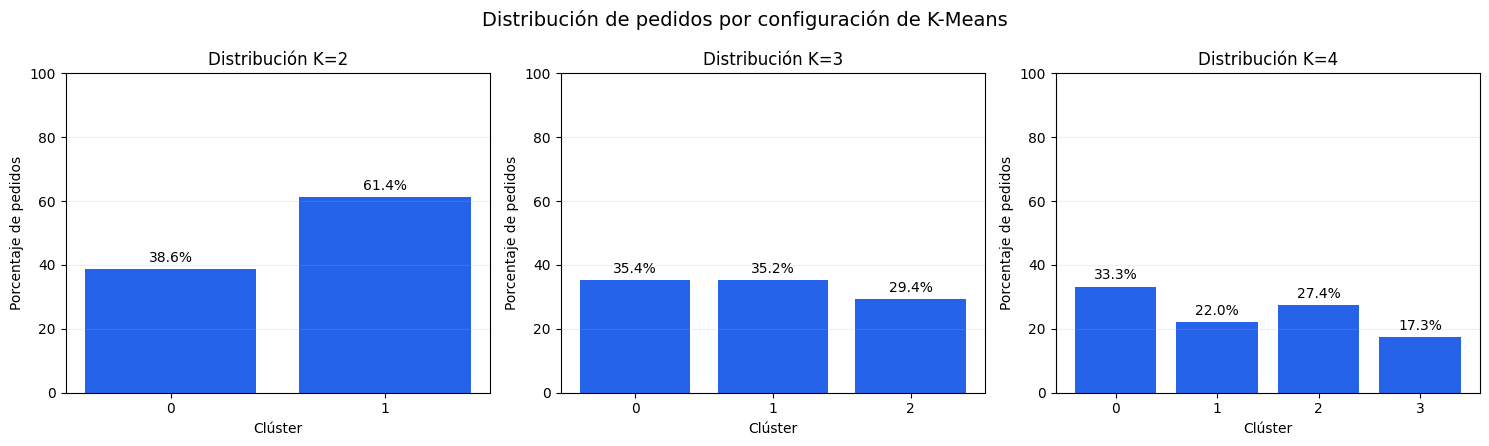

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, k in zip(axes, candidatos_k):

    perfil = perfiles_k_candidatos[k]
    barras = ax.bar(perfil.index.astype(str), perfil["porcentaje"], color="#2563eb")

    ax.bar_label(barras, fmt="%.1f%%",padding=3)
    ax.set_title(f"Distribución K={k}")
    ax.set_xlabel("Clúster")
    ax.set_ylabel("Porcentaje de pedidos")
    ax.set_ylim(0, 100)
    ax.grid(axis="y", alpha=0.2)

plt.suptitle("Distribución de pedidos por configuración de K-Means", fontsize=14)

plt.tight_layout()
plt.show()



### 4.7. Comparación de perfiles comerciales

Se comparan las características promedio de los clústeres para las tres configuraciones evaluadas.

La visualización permite identificar diferencias en edad, cantidad de productos y ventas netas, facilitando la selección de una segmentación útil para el análisis comercial.


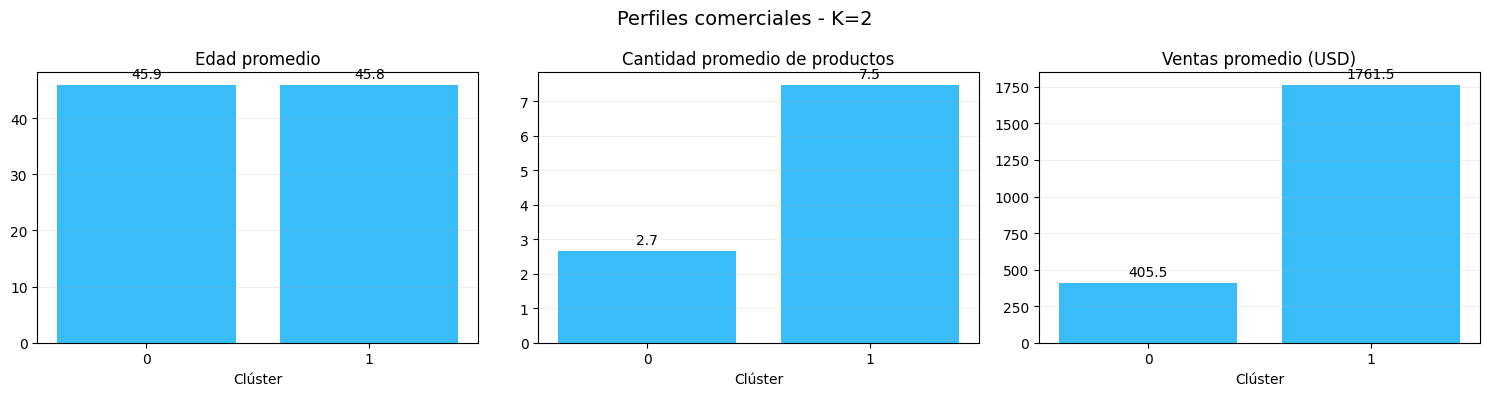

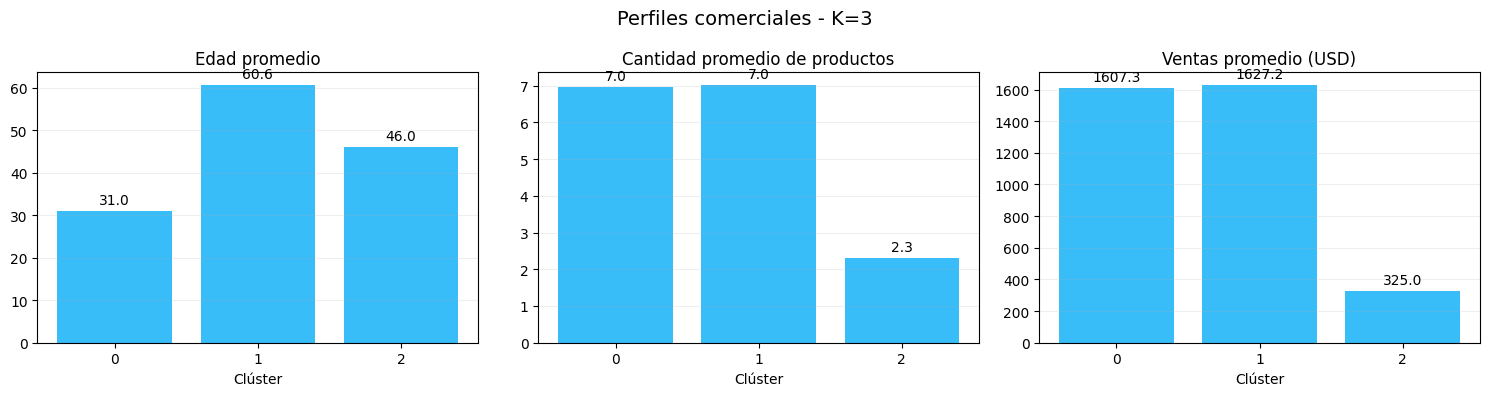

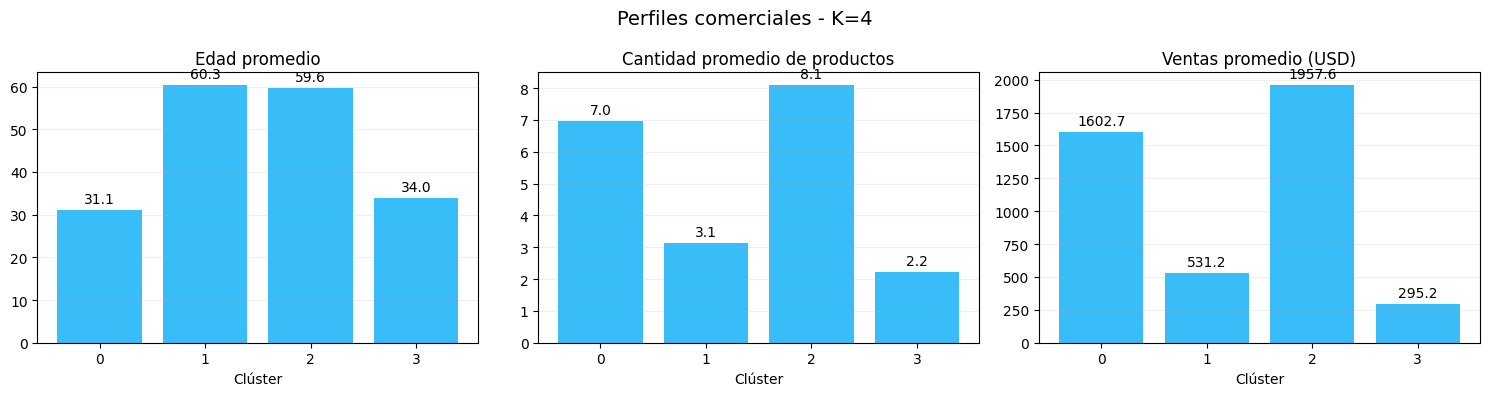

In [34]:

variables_perfil = [
    "edad_promedio",
    "cantidad_promedio",
    "ventas_promedio"
]

titulos_perfil = [
    "Edad promedio",
    "Cantidad promedio de productos",
    "Ventas promedio (USD)"
]

for k in candidatos_k:

    perfil = perfiles_k_candidatos[k]

    fig, axes = plt.subplots(
        1, 3, figsize=(15, 4)
    )

    for ax, variable, titulo in zip(
        axes, variables_perfil, titulos_perfil
    ):

        barras = ax.bar(
            perfil.index.astype(str),
            perfil[variable],
            color="#38bdf8"
        )

        ax.bar_label(
            barras,
            fmt="%.1f",
            padding=3
        )

        ax.set_title(titulo)
        ax.set_xlabel("Clúster")
        ax.grid(axis="y", alpha=0.2)

    plt.suptitle(
        f"Perfiles comerciales - K={k}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()



### 4.8. Selección del modelo K-Means definitivo

Se selecciona K=4 considerando el método del codo y la interpretación comercial de los grupos.

Aunque K=2 presentó la mayor silueta (0,329), K=4 obtuvo un valor de 0,311 y permitió identificar cuatro perfiles diferenciados por edad, volumen de compra y ventas netas.

Se prioriza la utilidad interpretativa de los segmentos, reconociendo que su separación estadística es moderada.


In [35]:
# Seleccionar configuración definitiva
k_final = 4

modelo_kmeans_final = modelos_k_candidatos[k_final]

# Asignar etiquetas a los pedidos
df_segmentos["cluster_kmeans"] = (
    modelo_kmeans_final.predict(X_cluster)
)

# Nombres interpretativos según los perfiles obtenidos
nombres_clusters = {
    0: "Jóvenes - alto valor",
    1: "Mayores - menor valor",
    2: "Mayores - alto valor",
    3: "Jóvenes - menor valor"
}

df_segmentos["perfil_comercial"] = (
    df_segmentos["cluster_kmeans"].map(nombres_clusters)
)

# Perfil consolidado
perfil_final = perfiles_k_candidatos[k_final].copy()

perfil_final["segmento"] = (
    perfil_final.index.map(nombres_clusters)
)

print("MODELO K-MEANS DEFINITIVO")
print("Número de clústeres:", k_final)

display(perfil_final.round(2))

print("\nDISTRIBUCIÓN DE LOS GRUPOS")
display(
    df_segmentos["perfil_comercial"]
    .value_counts()
)


MODELO K-MEANS DEFINITIVO
Número de clústeres: 4


,pedidos,edad_promedio,cantidad_promedio,ventas_promedio,ventas_mediana,porcentaje,segmento
cluster,,,,,,,
0,27470,31.100,6.960,"1,602.700","1,301.460",33.260,Jóvenes - alto valor
1,18202,60.310,3.140,531.160,460.520,22.040,Mayores - menor valor
2,22639,59.560,8.090,"1,957.620","1,640.910",27.410,Mayores - alto valor
3,14289,33.960,2.220,295.150,243.310,17.300,Jóvenes - menor valor



DISTRIBUCIÓN DE LOS GRUPOS


,count
perfil_comercial,
Jóvenes - alto valor,27470
Mayores - alto valor,22639
Mayores - menor valor,18202
Jóvenes - menor valor,14289



### 4.9. Visualización de clústeres mediante PCA

Se aplica Análisis de Componentes Principales (PCA) para proyectar las tres variables utilizadas en K-Means sobre un espacio bidimensional.

La visualización permite examinar la distribución de los cuatro segmentos y sus posibles zonas de superposición.

PCA se utiliza únicamente con fines de visualización; los clústeres originales se obtuvieron en el espacio de tres variables estandarizadas.


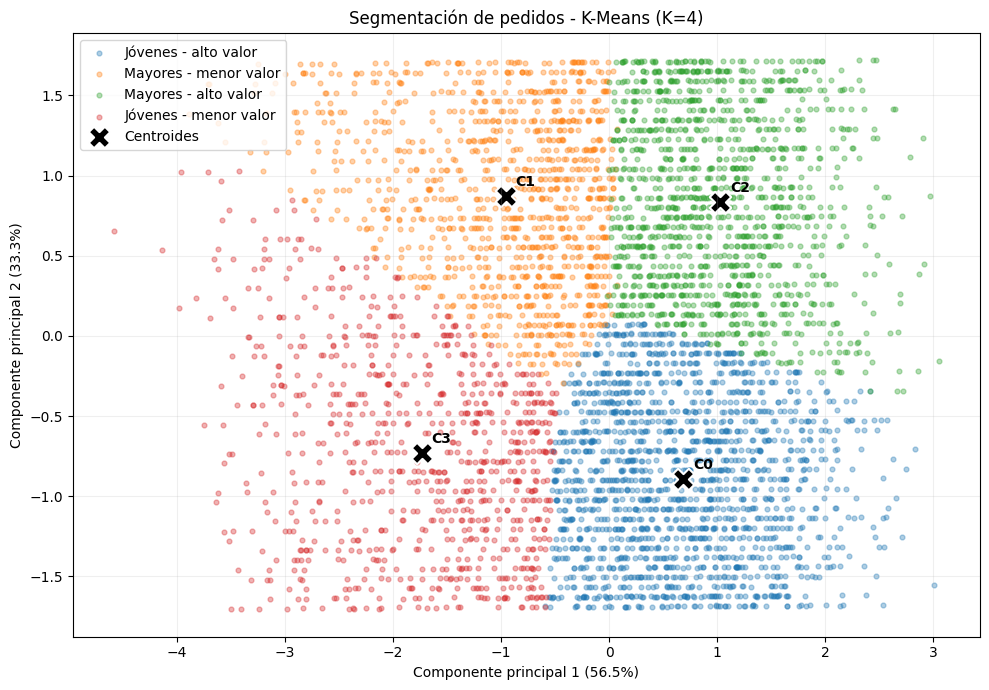

VARIANZA EXPLICADA POR PCA
PC1: 56.52%
PC2: 33.33%
Total: 89.85%


In [36]:
# Reducir de tres a dos dimensiones
pca_cluster = PCA(n_components=2)

X_cluster_pca = pca_cluster.fit_transform(X_cluster)

# Crear DataFrame para visualización
df_pca = pd.DataFrame({
    "PCA1": X_cluster_pca[:, 0],
    "PCA2": X_cluster_pca[:, 1],
    "cluster": df_segmentos["cluster_kmeans"].to_numpy()
})

# Muestra reproducible para visualizar
df_pca_muestra = df_pca.sample(
    n=min(5000, len(df_pca)),
    random_state=42
)

# Proyectar centroides originales
centroides_pca = pca_cluster.transform(
    modelo_kmeans_final.cluster_centers_
)

plt.figure(figsize=(10, 7))

# Dibujar cada grupo
for cluster in sorted(df_pca_muestra["cluster"].unique()):

    datos_cluster = df_pca_muestra[
        df_pca_muestra["cluster"] == cluster
    ]

    plt.scatter(
        datos_cluster["PCA1"],
        datos_cluster["PCA2"],
        s=12,
        alpha=0.35,
        label=nombres_clusters[cluster]
    )

# Mostrar centroides
plt.scatter(
    centroides_pca[:, 0],
    centroides_pca[:, 1],
    marker="X",
    s=240,
    c="black",
    edgecolors="white",
    linewidths=1.5,
    label="Centroides"
)

for i, centro in enumerate(centroides_pca):
    plt.annotate(
        f"C{i}",
        (centro[0], centro[1]),
        xytext=(7, 7),
        textcoords="offset points",
        fontweight="bold"
    )

plt.title("Segmentación de pedidos - K-Means (K=4)")
plt.xlabel(
    f"Componente principal 1 "
    f"({pca_cluster.explained_variance_ratio_[0]:.1%})"
)
plt.ylabel(
    f"Componente principal 2 "
    f"({pca_cluster.explained_variance_ratio_[1]:.1%})"
)

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("VARIANZA EXPLICADA POR PCA")
print(
    f"PC1: {pca_cluster.explained_variance_ratio_[0]:.2%}"
)
print(
    f"PC2: {pca_cluster.explained_variance_ratio_[1]:.2%}"
)
print(
    f"Total: {pca_cluster.explained_variance_ratio_.sum():.2%}"
)



### 4.10. Interpretación comercial de los segmentos

Se visualizan los perfiles de K-Means considerando la edad promedio, las ventas por pedido y el volumen de productos.

Esta representación facilita identificar los grupos de mayor y menor valor comercial y comprender las diferencias entre segmentos.

Las etiquetas describen patrones de pedidos y no necesariamente perfiles de clientes únicos.


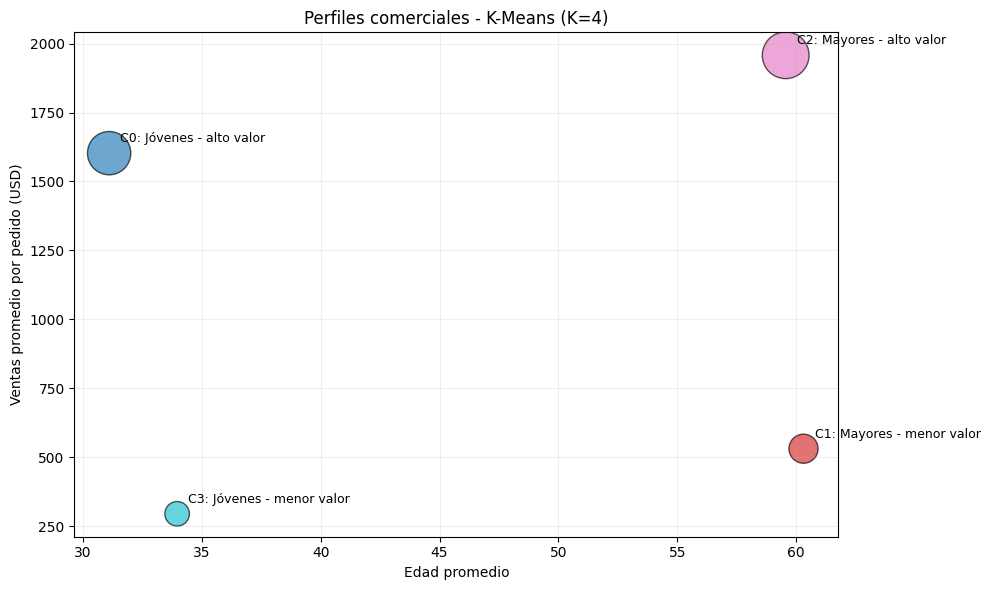

Tamaño de las burbujas: cantidad promedio de productos


In [37]:

fig, ax = plt.subplots(figsize=(10, 6))

# Tamaño proporcional a cantidad de productos
tamanios = perfil_final["cantidad_promedio"] * 140

scatter = ax.scatter(
    perfil_final["edad_promedio"],
    perfil_final["ventas_promedio"],
    s=tamanios,
    c=perfil_final.index,
    cmap="tab10",
    alpha=0.65,
    edgecolors="black",
    linewidths=1
)

# Etiquetas
for cluster, fila in perfil_final.iterrows():

    ax.annotate(
        f"C{cluster}: {fila['segmento']}",
        (
            fila["edad_promedio"],
            fila["ventas_promedio"]
        ),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=9
    )

ax.set_title("Perfiles comerciales - K-Means (K=4)")
ax.set_xlabel("Edad promedio")
ax.set_ylabel("Ventas promedio por pedido (USD)")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print(
    "Tamaño de las burbujas:",
    "cantidad promedio de productos"
)



### 4.11. Interpretación de la visualización PCA

Las dos componentes principales explican el 89,85 % de la variabilidad de las características utilizadas en la segmentación.

La proyección permite visualizar cuatro regiones asociadas con los perfiles comerciales identificados mediante K-Means.

Aunque los grupos muestran una distribución diferenciada, el coeficiente de silueta de 0,311 indica una separación moderada. Por tanto, los segmentos deben interpretarse como agrupaciones exploratorias de pedidos.



### 4.12. Segmentación mediante DBSCAN

Se implementa DBSCAN como segundo algoritmo de aprendizaje no supervisado.

A diferencia de K-Means, DBSCAN identifica grupos según la densidad de las observaciones, sin establecer previamente el número de clústeres.

Debido al tamaño del conjunto de datos, se utiliza una muestra reproducible de 8.000 pedidos, conservando las mismas variables estandarizadas de K-Means.

Se evaluarán diferentes valores de `eps` y se analizará la proporción de observaciones clasificadas como ruido.


In [38]:

# Seleccionar una muestra reproducible
rng_dbscan = np.random.default_rng(42)

indices_dbscan = rng_dbscan.choice(
    X_cluster.shape[0],
    size=min(8000, X_cluster.shape[0]),
    replace=False
)

# Muestra de los datos estandarizados
X_dbscan = X_cluster[indices_dbscan]

# Conservar registros originales para interpretación
df_dbscan = df_segmentos.iloc[
    indices_dbscan
].copy()

print("PREPARACIÓN PARA DBSCAN")
print("Registros de la muestra:", X_dbscan.shape[0])
print("Número de variables:", X_dbscan.shape[1])

print("\nVariables utilizadas:")
print(variables_kmeans)


PREPARACIÓN PARA DBSCAN
Registros de la muestra: 8000
Número de variables: 3

Variables utilizadas:
['customer_age', 'log_quantity', 'log_net_sales']



### 4.13. Selección del parámetro eps

Se utiliza el gráfico de distancias al vecino número 20 para orientar la selección del parámetro `eps`.

Este procedimiento permite identificar posibles cambios en la densidad de las observaciones y establecer valores candidatos para DBSCAN.

El parámetro definitivo se seleccionará considerando la cantidad de clústeres, la proporción de ruido y la calidad de separación.


REFERENCIAS PARA eps


,Percentil,Distancia
0,50,0.252
1,65,0.285
2,75,0.311
3,85,0.360
4,90,0.402
5,95,0.481


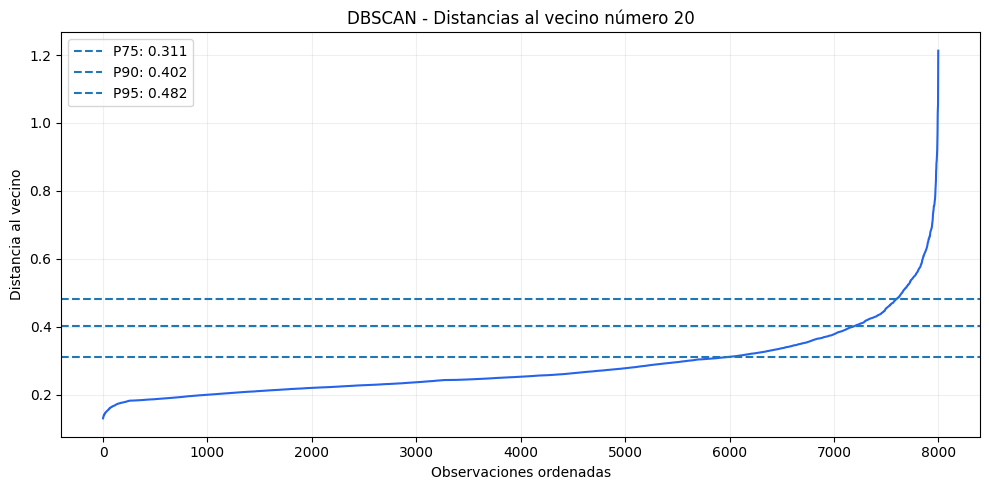

In [39]:

# Parámetro inicial
min_samples_dbscan = 20

# Vecinos más cercanos
vecinos = NearestNeighbors(
    n_neighbors=min_samples_dbscan,
    n_jobs=-1
)

vecinos.fit(X_dbscan)

# Calcular distancias
distancias, _ = vecinos.kneighbors(X_dbscan)

# Distancia al vecino número 20
distancias_k = np.sort(
    distancias[:, -1]
)

# Percentiles como referencia
percentiles = [50, 65, 75, 85, 90, 95]

valores_eps = np.percentile(
    distancias_k,
    percentiles
)

tabla_eps = pd.DataFrame({
    "Percentil": percentiles,
    "Distancia": valores_eps
})

print("REFERENCIAS PARA eps")
display(tabla_eps.round(4))

# Visualización
plt.figure(figsize=(10, 5))

plt.plot(
    distancias_k,
    color="#2563eb",
    linewidth=1.5
)

for percentil in [75, 90, 95]:

    valor = np.percentile(
        distancias_k,
        percentil
    )

    plt.axhline(
        valor,
        linestyle="--",
        label=f"P{percentil}: {valor:.3f}"
    )

plt.title("DBSCAN - Distancias al vecino número 20")
plt.xlabel("Observaciones ordenadas")
plt.ylabel("Distancia al vecino")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()



### 4.14. Evaluación de configuraciones DBSCAN

Se comparan diferentes valores de `eps`, manteniendo inicialmente `min_samples=20`.

Para cada configuración se registra el número de clústeres encontrados, el porcentaje de ruido y el coeficiente de silueta cuando sea posible calcularlo.

La selección considera tanto la calidad de los grupos como la proporción de observaciones que permanecen sin asignación.


In [40]:

# Valores candidatos derivados de las distancias
eps_candidatos = np.unique(np.round(np.percentile( distancias_k,[50, 65, 75, 85, 90, 95]), 4))

# Evitar eps igual a cero
eps_candidatos = eps_candidatos[eps_candidatos > 0]

resultados_dbscan = []

for eps in eps_candidatos:

    modelo_db = DBSCAN(
        eps=float(eps),
        min_samples=min_samples_dbscan,
        n_jobs=-1)

    etiquetas = modelo_db.fit_predict(X_dbscan)

    # DBSCAN utiliza -1 para representar ruido
    mascara_validos = etiquetas != -1

    n_clusters = len(set(etiquetas) - {-1})

    porcentaje_ruido = (np.mean(etiquetas == -1) * 100)

    # Silueta de observaciones no clasificadas como ruido
    silueta = np.nan

    if n_clusters >= 2:

        X_validos = X_dbscan[mascara_validos]
        etiquetas_validas = etiquetas[mascara_validos]

        if (
            len(X_validos) > n_clusters
            and len(X_validos) <= 1500
        ):
            silueta = silhouette_score(
                X_validos,
                etiquetas_validas
            )

        elif len(X_validos) > 1500:

            # Muestra estratificada para conservar clústeres
            rng_sil = np.random.default_rng(42)

            indices_sil = []

            for cluster in np.unique(etiquetas_validas):
                posiciones = np.where(
                    etiquetas_validas == cluster
                )[0]

                # Incluir al menos un registro por clúster
                cantidad = min(2, len(posiciones))

                indices_sil.extend(
                    rng_sil.choice(
                        posiciones,
                        size=cantidad,
                        replace=False
                    )
                )

            if len(indices_sil) <= 1500:
                restantes = np.setdiff1d(
                    np.arange(len(X_validos)),
                    indices_sil
                )

                adicionales = rng_sil.choice(
                    restantes,
                    size=min(
                        1500 - len(indices_sil),
                        len(restantes)
                    ),
                    replace=False
                )

                indices_sil = np.concatenate([
                    indices_sil,
                    adicionales
                ])

                etiquetas_sil = etiquetas_validas[indices_sil]

                if 1 < len(np.unique(etiquetas_sil)) < len(indices_sil):
                    silueta = silhouette_score(
                        X_validos[indices_sil],
                        etiquetas_sil
                    )

    resultados_dbscan.append({
        "eps": eps,
        "min_samples": min_samples_dbscan,
        "Clusters": n_clusters,
        "Ruido (%)": porcentaje_ruido,
        "Cobertura (%)": 100 - porcentaje_ruido,
        "Silueta": silueta
    })

resultados_dbscan = pd.DataFrame(
    resultados_dbscan
)

print("COMPARACIÓN DE CONFIGURACIONES DBSCAN")
display(resultados_dbscan.round(4))


COMPARACIÓN DE CONFIGURACIONES DBSCAN


,eps,min_samples,Clusters,Ruido (%),Cobertura (%),Silueta
0,0.252,20,14,28.550,71.450,-0.113
1,0.285,20,13,16.387,83.612,-0.019
2,0.311,20,6,10.950,89.050,0.095
3,0.360,20,5,5.325,94.675,0.127
4,0.402,20,4,2.925,97.075,0.140
5,0.481,20,3,0.850,99.150,0.213



### 4.15. Selección de parámetros de DBSCAN

El análisis de distancias sugiere valores de `eps` entre 0,4 y 0,5.

Se seleccionan dos configuraciones candidatas: `eps=0.402`, con cuatro clústeres, y `eps=0.481`, con tres clústeres y mayor coeficiente de silueta.

Se comparan el tamaño y las características comerciales de los grupos para determinar si las configuraciones producen segmentos representativos e interpretables.


In [41]:

# Configuraciones seleccionadas
eps_seleccionados = [0.402, 0.481]

modelos_dbscan = {}
perfiles_dbscan = {}

for eps in eps_seleccionados:

    # Entrenar DBSCAN
    modelo = DBSCAN(eps=eps, min_samples=20, n_jobs=-1)

    etiquetas = modelo.fit_predict(X_dbscan)

    modelos_dbscan[eps] = modelo

    # Asociar etiquetas a los pedidos
    df_perfil_db = df_dbscan.copy()
    df_perfil_db["cluster_dbscan"] = etiquetas

    # Calcular perfiles incluyendo el ruido (-1)
    perfil = df_perfil_db.groupby(
        "cluster_dbscan"
    ).agg(
        pedidos=("cluster_dbscan", "size"),
        edad_promedio=("customer_age", "mean"),
        cantidad_promedio=("quantity", "mean"),
        ventas_promedio=("net_sales", "mean"),
        ventas_mediana=("net_sales", "median")
    )

    perfil["porcentaje"] = (
        perfil["pedidos"] / len(df_perfil_db) * 100
    )

    perfiles_dbscan[eps] = perfil

    print(f"\nPERFILES DBSCAN - eps={eps}")
    display(perfil.round(2))

    # Diagnóstico de distribución
    grupos_validos = perfil.drop(
        index=-1, errors="ignore"
    )

    mayor_grupo = grupos_validos["pedidos"].max()

    porcentaje_mayor = (
        mayor_grupo / len(df_perfil_db) * 100
    )

    print(
        f"Mayor clúster: {porcentaje_mayor:.2f}% "
        "de la muestra"
    )

    if porcentaje_mayor > 90:
        print(
            "Advertencia: un clúster concentra "
            "más del 90% de las observaciones."
        )



PERFILES DBSCAN - eps=0.402


,pedidos,edad_promedio,cantidad_promedio,ventas_promedio,ventas_mediana,porcentaje
cluster_dbscan,,,,,,
-1,234,46.440,5.030,"1,118.460",128.910,2.920
0,5456,45.920,7.130,"1,582.040","1,294.910",68.200
1,798,45.750,2.000,478.790,372.960,9.980
2,567,45.980,1.000,217.970,165.230,7.090
3,945,46.050,3.000,681.340,561.780,11.810


Mayor clúster: 68.20% de la muestra

PERFILES DBSCAN - eps=0.481


,pedidos,edad_promedio,cantidad_promedio,ventas_promedio,ventas_mediana,porcentaje
cluster_dbscan,,,,,,
-1,68,48.620,4.630,964.350,53.380,0.850
0,6498,45.940,6.540,"1,453.300","1,139.640",81.230
1,822,45.810,2.000,471.140,359.790,10.270
2,612,45.720,1.000,239.270,172.700,7.650


Mayor clúster: 81.23% de la muestra



### 4.16. Visualización de DBSCAN mediante PCA

Se proyectan las agrupaciones de DBSCAN en el espacio PCA utilizado previamente para K-Means.

Se comparan las configuraciones seleccionadas, diferenciando los clústeres identificados y las observaciones clasificadas como ruido.

La visualización permite examinar la distribución espacial de los grupos y detectar posibles problemas de concentración o fragmentación.


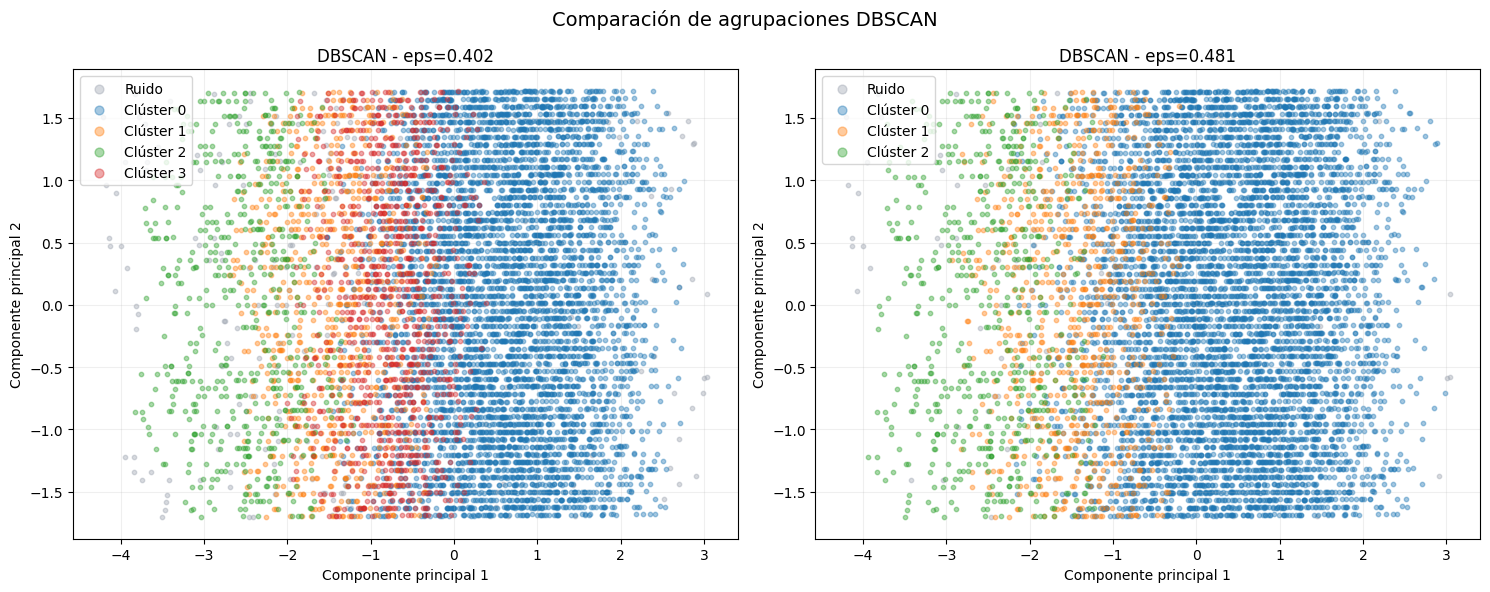

In [42]:

# Proyectar la muestra en el PCA ya ajustado
X_dbscan_pca = pca_cluster.transform(X_dbscan)

fig, axes = plt.subplots(
    1, 2, figsize=(15, 6)
)

for ax, eps in zip(axes, eps_seleccionados):

    etiquetas = modelos_dbscan[eps].labels_

    for cluster in np.unique(etiquetas):

        mascara = etiquetas == cluster

        if cluster == -1:
            etiqueta = "Ruido"
            color = "#9ca3af"
        else:
            etiqueta = f"Clúster {cluster}"
            color = plt.cm.tab10(
                int(cluster) % 10
            )

        ax.scatter(
            X_dbscan_pca[mascara, 0],
            X_dbscan_pca[mascara, 1],
            s=10,
            alpha=0.4,
            color=color,
            label=etiqueta
        )

    ax.set_title(f"DBSCAN - eps={eps}")
    ax.set_xlabel("Componente principal 1")
    ax.set_ylabel("Componente principal 2")
    ax.legend(markerscale=2)
    ax.grid(alpha=0.2)

plt.suptitle(
    "Comparación de agrupaciones DBSCAN",
    fontsize=14
)

plt.tight_layout()
plt.show()



### 4.17. Análisis de representatividad de DBSCAN

Se analiza la concentración de observaciones en los grupos identificados por DBSCAN.

Una configuración con alta cobertura y buena silueta puede resultar poco útil si la mayoría de los pedidos pertenece a un único clúster.

La evaluación final considerará conjuntamente el número de grupos, la proporción de ruido, la concentración de observaciones y la interpretación comercial.


In [43]:
def silueta_clustering(X, etiquetas):
    n_grupos = np.unique(etiquetas).size
    if 2 <= n_grupos < len(etiquetas):
        return silhouette_score(X, etiquetas)
    return np.nan


resumen_dbscan = []

for eps in eps_seleccionados:
    etiquetas = modelos_dbscan[eps].labels_
    sin_ruido = etiquetas != -1
    etiquetas_validas = etiquetas[sin_ruido]
    grupos, conteos = np.unique(etiquetas_validas, return_counts=True)

    resumen_dbscan.append({
        "eps": eps,
        "Clústeres": len(grupos),
        "Ruido (%)": 100 * (~sin_ruido).mean(),
        "Mayor clúster (%)": (
            100 * conteos.max() / len(etiquetas) if len(conteos) else np.nan
        ),
        "Silueta": silueta_clustering(X_dbscan[sin_ruido], etiquetas_validas),
    })

resumen_dbscan = pd.DataFrame(resumen_dbscan)
display(resumen_dbscan.round(4))


,eps,Clústeres,Ruido (%),Mayor clúster (%),Silueta
0,0.402,4,2.925,68.200,0.134
1,0.481,3,0.850,81.225,0.208


### 4.18. Comparación y conclusiones del clustering

K-Means se ajustó sobre todos los pedidos en USD y DBSCAN sobre una muestra reproducible de 8.000 pedidos. Para comparar sus siluetas, se usan los mismos pedidos de esa muestra. Se excluyen de ambos cálculos las filas marcadas como ruido por DBSCAN y se reporta el porcentaje de ruido por separado.

La columna `Registros` indica cuántos pedidos se usaron para ajustar cada modelo. La columna `Registros para silueta` indica cuántos pedidos se usaron en la comparación. Se elige K-Means con K=4 como modelo principal por el resultado del método del codo y la utilidad de sus cuatro perfiles comerciales.


In [44]:
modelo_clustering_final = modelo_kmeans_final

eps_dbscan_final = 0.481
modelo_dbscan_final = modelos_dbscan[eps_dbscan_final]
fila_dbscan_final = resumen_dbscan.set_index("eps").loc[eps_dbscan_final]

etiquetas_dbscan = modelo_dbscan_final.labels_
df_dbscan_final = df_dbscan.copy()
df_dbscan_final["cluster_dbscan"] = etiquetas_dbscan

# Evaluar K-Means sobre las mismas filas usadas para la silueta de DBSCAN.
sin_ruido_dbscan = etiquetas_dbscan != -1
X_comun = X_dbscan[sin_ruido_dbscan]
etiquetas_kmeans_comun = modelo_clustering_final.predict(X_dbscan)[sin_ruido_dbscan]
silueta_kmeans_comun = silueta_clustering(X_comun, etiquetas_kmeans_comun)

resumen_clustering_final = pd.DataFrame({
    "Modelo": ["K-Means", "DBSCAN"],
    "Configuración": [
        f"K={modelo_clustering_final.n_clusters}",
        f"eps={eps_dbscan_final}, min_samples={modelo_dbscan_final.min_samples}",
    ],
    "Clústeres": [
        modelo_clustering_final.n_clusters,
        int(fila_dbscan_final["Clústeres"]),
    ],
    "Registros": [len(X_cluster), len(X_dbscan)],
    "Silueta": [silueta_kmeans_comun, fila_dbscan_final["Silueta"]],
    "Ruido (%)": [0.0, fila_dbscan_final["Ruido (%)"]],
    "Registros para silueta": [len(X_comun), len(X_comun)],
})

display(resumen_clustering_final.round(4))

,Modelo,Configuración,Clústeres,Registros,Silueta,Ruido (%),Registros para silueta
0,K-Means,K=4,4,82600,0.303,0.000,7932
1,DBSCAN,"eps=0.481, min_samples=20",3,8000,0.208,0.850,7932


### 4.19. Decisiones comerciales para los perfiles de K-Means

Los cuatro clústeres describen pedidos en USD. El perfil se asigna una vez registrado el importe del pedido, porque la variable `net_sales` interviene en la segmentación. Las acciones se plantean para la siguiente interacción comercial.

| Clúster | Perfil del pedido | Acción a evaluar | Indicadores del piloto |
|---|---|---|---|
| C0 · Jóvenes, alto valor | 6,96 unidades y <br> 1.602,70 USD en promedio | Probar una oferta de paquetes <br> de productos complementarios a la <br> compra anterior. | Proporción de compras siguientes <br> que incluyen el paquete y margen <br> por cliente contactado. |
| C1 · Mayores, menor valor | 3,14 unidades y <br> 531,16 USD en promedio | Recomendar un producto <br> complementario a precio regular <br> tras la compra. | Unidades por pedido <br> siguiente y tasa de recompra. |
| C2 · Mayores, alto valor | 8,09 unidades y <br> 1.957,62 USD en promedio | Probar un beneficio de fidelización <br> aplicable a la próxima compra. | Tasa de recompra a 30 días <br>y margen por cliente contactado. |
| C3 · Jóvenes, menor valor | 2,22 unidades y <br> 295,15 USD en promedio | Probar un combo de entrada de bajo <br> precio para una compra posterior. | Tasa de recompra y venta <br>neta por cliente contactado. |

La base simulada permite formular estas propuestas como hipótesis. En un piloto con datos reales, se tomaría el último pedido completado en USD de cada cliente y se asignaría al azar, dentro de cada perfil, quién recibe la acción y quién continúa con la gestión habitual. Los indicadores se medirían en una ventana de 30 días. La asignación por cliente evita que sus distintos pedidos lo ubiquen en ambos grupos del piloto.


## 5. Red neuronal multicapa (MLP) con PyTorch

Se implementa una red neuronal MLP para predecir `net_sales` utilizando los mismos predictores y particiones empleados en la regresión avanzada.

La arquitectura incluye dos capas ocultas con activación ReLU y una neurona de salida para la predicción continua.

Se utiliza la función de pérdida MSE, el optimizador Adam y parada temprana para reducir el riesgo de sobreajuste. El rendimiento se comparará con Ridge y Random Forest.


In [45]:


# Reproducibilidad
np.random.seed(42)
torch.manual_seed(42)

# Seleccionar dispositivo
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo:", device)

# Preprocesamiento exclusivo para MLP
preprocesador_mlp = ColumnTransformer(
    transformers=[
        ("numericas",
         StandardScaler(),
         numericas_reg_f3),

        ("categoricas",
         OneHotEncoder(handle_unknown="ignore"),
         categoricas_reg_f3)
    ],
    sparse_threshold=0.0
)

# Ajustar únicamente sobre entrenamiento
X_mlp_train = preprocesador_mlp.fit_transform(
    X_reg_train_f3
).astype(np.float32)

X_mlp_val = preprocesador_mlp.transform(
    X_reg_val_f3
).astype(np.float32)

# Escalar variable objetivo
escalador_y_mlp = StandardScaler()

y_mlp_train = escalador_y_mlp.fit_transform(
    np.asarray(y_reg_train).reshape(-1, 1)
).astype(np.float32)

y_mlp_val = escalador_y_mlp.transform(
    np.asarray(y_reg_val).reshape(-1, 1)
).astype(np.float32)

# Crear tensores
X_train_tensor = torch.from_numpy(X_mlp_train)
y_train_tensor = torch.from_numpy(y_mlp_train)

X_val_tensor = torch.from_numpy(
    X_mlp_val
).to(device)

y_val_tensor = torch.from_numpy(
    y_mlp_val
).to(device)

# Crear DataLoader
dataset_train_mlp = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

loader_train_mlp = DataLoader(
    dataset_train_mlp,
    batch_size=256,
    shuffle=True,
    num_workers=0
)

print("\nDATOS PREPARADOS PARA MLP")
print("Entrenamiento:", X_mlp_train.shape)
print("Validación:", X_mlp_val.shape)
print("Número de características:", X_mlp_train.shape[1])


Dispositivo: cpu

DATOS PREPARADOS PARA MLP
Entrenamiento: (57820, 34)
Validación: (12390, 34)
Número de características: 34



### 5.1. Arquitectura y entrenamiento de la red neuronal

Se construye una red MLP con dos capas ocultas de 64 y 32 neuronas, respectivamente, utilizando activaciones ReLU.

La red se entrena con Adam y regularización L2 mediante `weight_decay`. Se incorpora parada temprana basada en la pérdida de validación, conservando los parámetros de la mejor época.

La función de pérdida es MSE, calculada sobre la variable objetivo estandarizada.


In [46]:

# Definir arquitectura
modelo_mlp = nn.Sequential(
    nn.Linear(X_mlp_train.shape[1], 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
).to(device)

# Función de pérdida
criterio_mlp = nn.MSELoss()

# Optimizador
optimizador_mlp = torch.optim.Adam(
    modelo_mlp.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# Configuración del entrenamiento
max_epocas = 35
paciencia = 6
mejor_perdida = float("inf")
epocas_sin_mejora = 0

historial_mlp = []
mejores_pesos = None

for epoca in range(1, max_epocas + 1):

    modelo_mlp.train()
    perdida_acumulada = 0.0

    # Entrenamiento por lotes
    for X_batch, y_batch in loader_train_mlp:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizador_mlp.zero_grad()

        predicciones = modelo_mlp(X_batch)

        perdida = criterio_mlp(
            predicciones, y_batch
        )

        perdida.backward()
        optimizador_mlp.step()

        perdida_acumulada += (
            perdida.item() * len(X_batch)
        )

    perdida_train = (
        perdida_acumulada / len(dataset_train_mlp)
    )

    # Evaluación en validación
    modelo_mlp.eval()

    with torch.no_grad():
        pred_val = modelo_mlp(X_val_tensor)

        perdida_val = criterio_mlp(
            pred_val, y_val_tensor
        ).item()

    historial_mlp.append({
        "Epoca": epoca,
        "MSE_train": perdida_train,
        "MSE_val": perdida_val
    })

    print(
        f"Época {epoca:02d} | "
        f"Train: {perdida_train:.5f} | "
        f"Val: {perdida_val:.5f}"
    )

    # Parada temprana
    if perdida_val < mejor_perdida - 1e-5:

        mejor_perdida = perdida_val
        mejores_pesos = deepcopy(
            modelo_mlp.state_dict()
        )
        epocas_sin_mejora = 0

    else:
        epocas_sin_mejora += 1

        if epocas_sin_mejora >= paciencia:
            print("\nParada temprana activada.")
            break

# Recuperar los mejores parámetros
modelo_mlp.load_state_dict(mejores_pesos)

historial_mlp = pd.DataFrame(historial_mlp)

print("\nENTRENAMIENTO FINALIZADO")
print("Mejor MSE de validación:", round(mejor_perdida, 5))


Época 01 | Train: 0.67645 | Val: 0.61518
Época 02 | Train: 0.62943 | Val: 0.61133
Época 03 | Train: 0.62601 | Val: 0.60961
Época 04 | Train: 0.62463 | Val: 0.61275
Época 05 | Train: 0.62277 | Val: 0.60981
Época 06 | Train: 0.62258 | Val: 0.61354
Época 07 | Train: 0.62228 | Val: 0.61151
Época 08 | Train: 0.62171 | Val: 0.61076
Época 09 | Train: 0.61957 | Val: 0.61156

Parada temprana activada.

ENTRENAMIENTO FINALIZADO
Mejor MSE de validación: 0.60961



### 5.2. Evolución de la función de pérdida

Se visualiza la evolución del error cuadrático medio durante las épocas de entrenamiento.

Las curvas permiten analizar la convergencia del modelo y detectar posibles diferencias entre entrenamiento y validación.

La parada temprana busca conservar la configuración con menor pérdida de validación y evitar entrenamientos innecesarios.


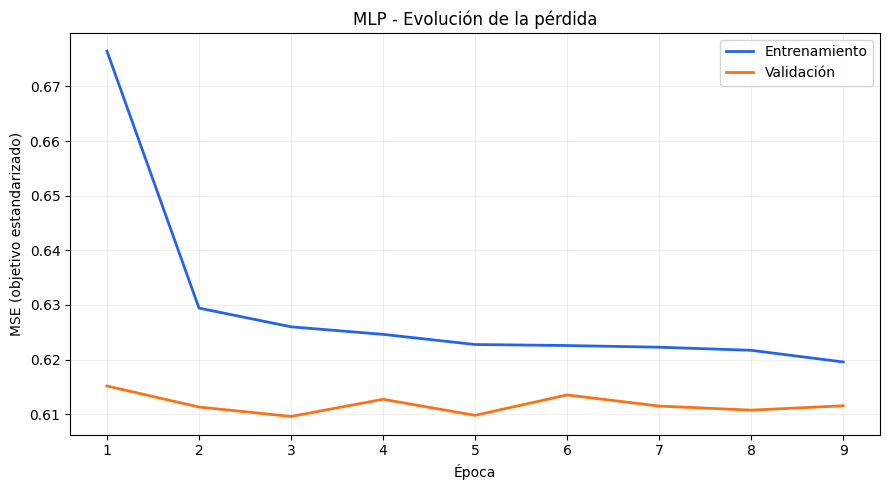

In [47]:

plt.figure(figsize=(9, 5))

plt.plot(
    historial_mlp["Epoca"],
    historial_mlp["MSE_train"],
    label="Entrenamiento",
    linewidth=2,
    color="#2563eb"
)

plt.plot(
    historial_mlp["Epoca"],
    historial_mlp["MSE_val"],
    label="Validación",
    linewidth=2,
    color="#f97316"
)

plt.title("MLP - Evolución de la pérdida")
plt.xlabel("Época")
plt.ylabel("MSE (objetivo estandarizado)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [48]:

# Obtener predicciones con la mejor red
modelo_mlp.eval()

with torch.no_grad():
    pred_mlp_train_scaled = modelo_mlp(
        X_train_tensor.to(device)
    ).cpu().numpy()

    pred_mlp_val_scaled = modelo_mlp(
        X_val_tensor
    ).cpu().numpy()

# Recuperar escala original (USD)
pred_mlp_train = escalador_y_mlp.inverse_transform(
    pred_mlp_train_scaled
).ravel()

pred_mlp_val = escalador_y_mlp.inverse_transform(
    pred_mlp_val_scaled
).ravel()

# Evaluar métricas
resultados_mlp = pd.DataFrame({
    "Entrenamiento": evaluar_regresion_f3(
        y_reg_train,
        pred_mlp_train
    ),
    "Validación": evaluar_regresion_f3(
        y_reg_val,
        pred_mlp_val
    )
}).T

print("RESULTADOS - MLP")
display(resultados_mlp.round(4))

# Comparar con modelos anteriores
comparacion_mlp = pd.DataFrame({
    "Ridge": resultados_ridge.loc["Validación"],
    "Random Forest optimizado":
        resultados_rf_opt.loc["Validación"],
    "MLP": resultados_mlp.loc["Validación"]
}).T

print("\nCOMPARACIÓN DE REGRESIÓN - VALIDACIÓN")
display(comparacion_mlp.round(4))


RESULTADOS - MLP


,MAE,RMSE,R2
Entrenamiento,614.742,893.967,0.377
Validación,611.091,884.535,0.366



COMPARACIÓN DE REGRESIÓN - VALIDACIÓN


,MAE,RMSE,R2
Ridge,616.934,888.476,0.360
Random Forest optimizado,609.484,880.403,0.372
MLP,611.091,884.535,0.366



### 5.3. Resultados y conclusiones de la red neuronal MLP

La red neuronal MLP obtuvo un MAE de 611,091 USD, RMSE de 884,535 USD y R² de 0,366 en validación.

La curva de pérdida mostró una reducción inicial del error y posterior estabilización de la pérdida de validación. La parada temprana permitió conservar los mejores parámetros del entrenamiento.

Aunque la MLP superó a Ridge, no alcanzó el rendimiento de Random Forest optimizado, que mantiene el menor RMSE de validación (880,403 USD).

Se conserva Random Forest optimizado como candidato principal de regresión y la MLP como modelo comparativo.



## 6. Interpretabilidad de los modelos

Se utiliza Permutation Feature Importance para identificar las características con mayor contribución predictiva.

La técnica mide el deterioro del rendimiento al alterar aleatoriamente una variable, manteniendo las demás constantes.

Se analizarán los modelos Random Forest seleccionados para regresión y clasificación, utilizando muestras del conjunto de validación.


IMPORTANCIA DE VARIABLES - REGRESIÓN


,Variable,Importancia_RMSE,Desviacion
3,quantity,452.659,8.860
8,order_month,21.311,6.314
1,customer_segment,0.724,0.469
7,marketing_channel,0.338,0.185
9,is_weekend,0.164,0.032
6,shipping_method,0.158,0.061
4,customer_country,0.000,0.000
5,payment_method,-0.032,0.291
2,sales_channel,-0.127,0.112
0,customer_age,-0.189,0.247


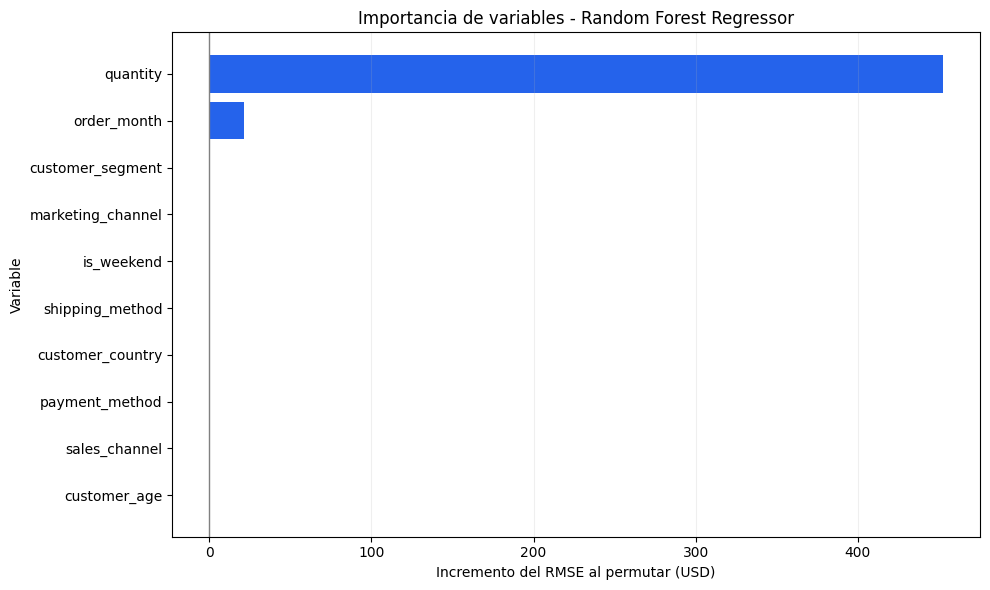

In [49]:
# Muestra reproducible de validación
rng_imp = np.random.default_rng(42)

indices_reg_imp = rng_imp.choice(len(X_reg_val_f3),size=min(2500, len(X_reg_val_f3)), replace=False)

X_reg_imp = X_reg_val_f3.iloc[indices_reg_imp]
y_reg_imp = np.asarray(y_reg_val).ravel()[indices_reg_imp]

# Calcular importancia por permutación
importancias_reg = permutation_importance(
    modelo_rf_optimizado,
    X_reg_imp,
    y_reg_imp,
    scoring="neg_root_mean_squared_error",
    n_repeats=4,
    random_state=42,
    n_jobs=1
)

# Crear tabla de importancias
df_importancias_reg = pd.DataFrame({
    "Variable": X_reg_imp.columns,
    "Importancia_RMSE": importancias_reg.importances_mean,
    "Desviacion": importancias_reg.importances_std
}).sort_values(
    "Importancia_RMSE",
    ascending=False)

print("IMPORTANCIA DE VARIABLES - REGRESIÓN")
display(df_importancias_reg.round(4))

# Visualización de las 12 variables principales
top_reg = df_importancias_reg.head(12).sort_values( "Importancia_RMSE")

plt.figure(figsize=(10, 6))
plt.barh(top_reg["Variable"], top_reg["Importancia_RMSE"], color="#2563eb")

plt.axvline(0, color="gray", linewidth=1)
plt.title("Importancia de variables - Random Forest Regressor")
plt.xlabel("Incremento del RMSE al permutar (USD)")
plt.ylabel("Variable")
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()



### 6.1. Importancia de variables en clasificación

Se analiza la importancia de los predictores del Random Forest Classifier optimizado mediante Permutation Feature Importance.

Se utiliza Average Precision como métrica para considerar el desbalance de clases.

El análisis permite identificar las características que más contribuyen a distinguir pedidos completados y devueltos, sin asumir relaciones causales.


IMPORTANCIA DE VARIABLES - CLASIFICACIÓN


,Variable,Importancia_AP,Desviacion
4,quantity,0.017,0.003
9,order_month,0.011,0.003
6,payment_method,0.000,0.001
8,marketing_channel,0.000,0.000
10,is_weekend,0.000,0.000
2,customer_segment,0.000,0.000
7,shipping_method,-0.000,0.000
3,sales_channel,-0.000,0.000
0,currency,-0.001,0.000
5,customer_country,-0.001,0.000


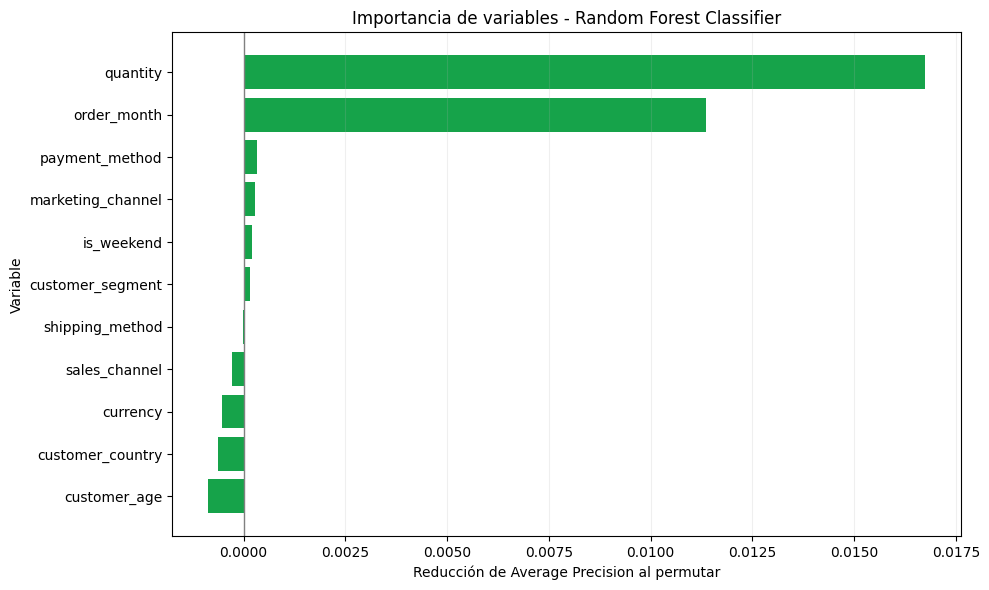

In [50]:

from sklearn.model_selection import StratifiedShuffleSplit

# Crear muestra estratificada de validación
muestreador = StratifiedShuffleSplit(
    n_splits=1,
    train_size=min(5000, len(X_clf_val_f3) - 2),
    random_state=42
)

indices_clf_imp, _ = next(
    muestreador.split(X_clf_val_f3, y_clf_val)
)

X_clf_imp = X_clf_val_f3.iloc[indices_clf_imp]
y_clf_imp = np.asarray(y_clf_val).ravel()[indices_clf_imp]

# Calcular importancia por permutación
importancias_clf = permutation_importance(
    modelo_rf_clf_opt,
    X_clf_imp,
    y_clf_imp,
    scoring="average_precision",
    n_repeats=4,
    random_state=42,
    n_jobs=1
)

# Crear tabla
df_importancias_clf = pd.DataFrame({
    "Variable": X_clf_imp.columns,
    "Importancia_AP": importancias_clf.importances_mean,
    "Desviacion": importancias_clf.importances_std
}).sort_values(
    "Importancia_AP",
    ascending=False
)

print("IMPORTANCIA DE VARIABLES - CLASIFICACIÓN")
display(df_importancias_clf.round(5))

# Gráfica de las 12 variables más importantes
top_clf = df_importancias_clf.head(12).sort_values(
    "Importancia_AP"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_clf["Variable"],
    top_clf["Importancia_AP"],
    color="#16a34a"
)

plt.axvline(0, color="gray", linewidth=1)
plt.title("Importancia de variables - Random Forest Classifier")
plt.xlabel("Reducción de Average Precision al permutar")
plt.ylabel("Variable")
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()



### 6.2. Conclusiones de interpretabilidad

El análisis de importancia por permutación identificó `quantity` como el principal predictor de las ventas netas. Al alterar esta variable, el RMSE aumentó aproximadamente 452,66 USD.

La variable `order_month` también aportó información predictiva, mientras que las demás características mostraron contribuciones reducidas.

En clasificación, `quantity` y `order_month` fueron igualmente las variables más relevantes, aunque sus contribuciones a Average Precision fueron limitadas.

Estos resultados sugieren que la información disponible es más adecuada para estimar el valor de los pedidos que para anticipar devoluciones.



## 7. Evaluación final de modelos

Se evalúan los modelos seleccionados sobre los conjuntos de prueba reservados desde la Fase 2.

Esta evaluación permite estimar su capacidad de generalización sobre observaciones no utilizadas durante el entrenamiento, la optimización ni la selección de modelos.

Los resultados de prueba se consideran definitivos y no se utilizarán para realizar nuevos ajustes.



### 7.1. Evaluación final de regresión

Se evalúa Random Forest optimizado sobre el conjunto de prueba para estimar su capacidad de predicción de `net_sales`.

El modelo fue seleccionado previamente utilizando las métricas de validación.

Se calculan MAE, RMSE y R² y se comparan con los resultados de entrenamiento y validación para identificar posibles diferencias de generalización.


In [51]:

# Predicciones finales de regresión
pred_rf_test = modelo_rf_optimizado.predict(
    X_reg_test_f3
)

# Calcular métricas
metricas_reg_test = evaluar_regresion_f3(
    y_reg_test,
    pred_rf_test
)

# Consolidar resultados
resultados_reg_final = resultados_rf_opt.copy()

resultados_reg_final.loc["Prueba"] = metricas_reg_test

print("EVALUACIÓN FINAL - RANDOM FOREST REGRESSOR")
display(resultados_reg_final.round(4))

# Comparación entre validación y prueba
diferencia_rmse_test = (
    resultados_reg_final.loc["Prueba", "RMSE"]
    - resultados_reg_final.loc["Validación", "RMSE"]
)

print(
    f"\nDiferencia RMSE (Prueba - Validación): "
    f"{diferencia_rmse_test:.4f} USD"
)

print("\nMODELO EVALUADO:")
print("Random Forest Regressor optimizado")
print(busqueda_rf.best_params_)


EVALUACIÓN FINAL - RANDOM FOREST REGRESSOR


,MAE,RMSE,R2
Entrenamiento,613.296,889.518,0.384
Validación,609.484,880.403,0.372
Prueba,608.749,885.116,0.382



Diferencia RMSE (Prueba - Validación): 4.7128 USD

MODELO EVALUADO:
Random Forest Regressor optimizado
{'modelo__n_estimators': 100, 'modelo__min_samples_leaf': 40, 'modelo__max_features': 0.8, 'modelo__max_depth': 6}



### 7.2. Análisis gráfico de predicciones y residuos

Se comparan los valores reales y predichos en el conjunto de prueba.

Adicionalmente, se analiza la distribución de los residuos para identificar posibles sesgos sistemáticos, errores elevados y patrones que el modelo no consiga representar.

La línea diagonal en el gráfico de dispersión representa una predicción perfecta.


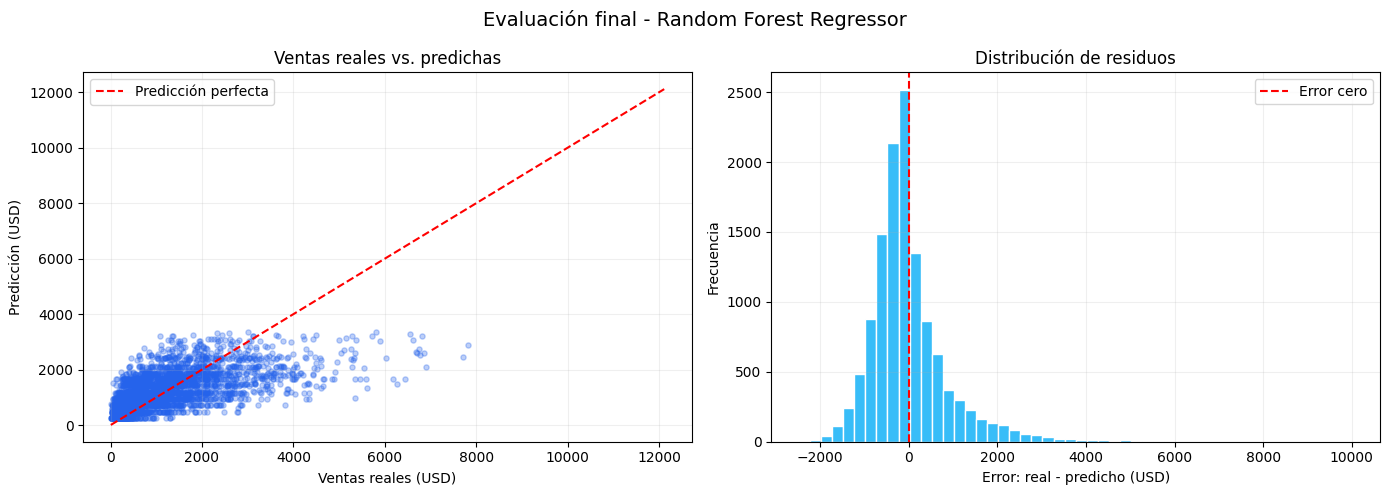

ANÁLISIS DE RESIDUOS
Error medio: -3.63 USD
Mediana del error: -164.76 USD
Desviación: 885.11 USD


In [52]:

# Valores reales y residuos
y_real_test = np.asarray(y_reg_test).ravel()

residuos_test = y_real_test - pred_rf_test

# Muestra para visualizar
rng_test = np.random.default_rng(42)

indices_test = rng_test.choice(
    len(y_real_test),
    size=min(3000, len(y_real_test)),
    replace=False
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico reales vs predichos
axes[0].scatter(
    y_real_test[indices_test],
    pred_rf_test[indices_test],
    alpha=0.3,
    s=14,
    color="#2563eb"
)

limite_min = min(
    y_real_test.min(),
    pred_rf_test.min()
)

limite_max = max(
    y_real_test.max(),
    pred_rf_test.max()
)

axes[0].plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    "r--",
    label="Predicción perfecta"
)

axes[0].set_title("Ventas reales vs. predichas")
axes[0].set_xlabel("Ventas reales (USD)")
axes[0].set_ylabel("Predicción (USD)")
axes[0].legend()
axes[0].grid(alpha=0.2)

# Distribución de residuos
axes[1].hist(
    residuos_test,
    bins=50,
    color="#38bdf8",
    edgecolor="white"
)

axes[1].axvline(
    0,
    linestyle="--",
    color="red",
    label="Error cero"
)

axes[1].set_title("Distribución de residuos")
axes[1].set_xlabel("Error: real - predicho (USD)")
axes[1].set_ylabel("Frecuencia")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.suptitle(
    "Evaluación final - Random Forest Regressor",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("ANÁLISIS DE RESIDUOS")
print(f"Error medio: {residuos_test.mean():.2f} USD")
print(f"Mediana del error: {np.median(residuos_test):.2f} USD")
print(f"Desviación: {residuos_test.std():.2f} USD")



### 7.3. Evaluación final de clasificación

Se evalúa Random Forest Classifier optimizado sobre el conjunto de prueba utilizando el umbral de 0,4911, seleccionado previamente en validación.

Se calculan Accuracy, Precision, Recall, F1-Score, AUC-ROC y Average Precision.

La evaluación busca determinar si el modelo mantiene su capacidad para detectar devoluciones y cuantificar las falsas alarmas generadas.


In [53]:

# Obtener probabilidades de devolución
proba_clf_test = modelo_clasificacion_candidato.predict_proba(
    X_clf_test_f3
)[:, 1]

# Aplicar umbral seleccionado en validación
pred_clf_test = (
    proba_clf_test >= umbral_clasificacion_candidato
).astype(int)

# Evaluar
metricas_clf_test = evaluar_clasificacion_f3(
    y_clf_test,
    pred_clf_test,
    proba_clf_test
)

# Consolidar resultados
resultados_clf_final = pd.DataFrame({
    "Validación": resultados_umbral.loc[
        "Umbral optimizado"
    ],
    "Prueba": metricas_clf_test
}).T

print("EVALUACIÓN FINAL - RANDOM FOREST CLASSIFIER")
display(resultados_clf_final.round(4))

print(
    f"\nUmbral utilizado: "
    f"{umbral_clasificacion_candidato:.4f}"
)

print("\nREPORTE DE CLASIFICACIÓN - PRUEBA")
print(classification_report(
    y_clf_test,
    pred_clf_test,
    target_names=["Completado", "Devuelto"],
    zero_division=0
))


EVALUACIÓN FINAL - RANDOM FOREST CLASSIFIER


,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Average Precision
Validación,0.337,0.086,0.786,0.154,0.557,0.091
Prueba,0.330,0.084,0.776,0.151,0.560,0.100



Umbral utilizado: 0.4911

REPORTE DE CLASIFICACIÓN - PRUEBA
              precision    recall  f1-score   support

  Completado       0.94      0.29      0.45     17034
    Devuelto       0.08      0.78      0.15      1420

    accuracy                           0.33     18454
   macro avg       0.51      0.53      0.30     18454
weighted avg       0.87      0.33      0.42     18454




### 7.4. Matriz de confusión final

Se representa la matriz de confusión del clasificador seleccionado sobre el conjunto de prueba.

El análisis permite cuantificar los pedidos correctamente clasificados, las devoluciones identificadas, los falsos positivos y las devoluciones no detectadas.

Se presta especial atención al equilibrio entre Recall y Precision, debido al desbalance de clases.


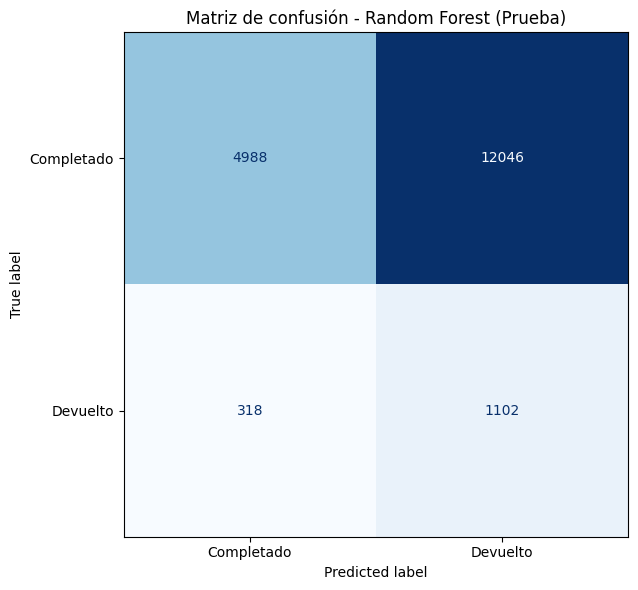

INTERPRETACIÓN DE LA MATRIZ
Verdaderos negativos: 4988
Falsos positivos: 12046
Falsos negativos: 318
Verdaderos positivos: 1102

Pedidos señalados como devolución: 13148
Devoluciones realmente detectadas: 1102


In [54]:
# Calcular matriz de confusión
matriz_clf_test = confusion_matrix(y_clf_test,pred_clf_test,labels=[0, 1])

# Visualización
fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(confusion_matrix=matriz_clf_test,display_labels=["Completado", "Devuelto"]
).plot(ax=ax,cmap="Blues",values_format="d",colorbar=False)

ax.set_title("Matriz de confusión - Random Forest (Prueba)")

plt.tight_layout()
plt.show()

# Interpretar resultados
tn, fp, fn, tp = matriz_clf_test.ravel()

print("INTERPRETACIÓN DE LA MATRIZ")
print(f"Verdaderos negativos: {tn}")
print(f"Falsos positivos: {fp}")
print(f"Falsos negativos: {fn}")
print(f"Verdaderos positivos: {tp}")

print(f"\nPedidos señalados como devolución: {tp + fp}")

print(f"Devoluciones realmente detectadas: {tp}")


## 8. Conclusiones de la evaluación final



### 8.1. Regresión

Random Forest optimizado obtuvo en prueba un **MAE de 608,75 USD**, un **RMSE de 885,12 USD** y un **R² de 0,382**. El RMSE subió **4,71 USD** respecto a validación. La mediana del residuo, calculado como valor real menos predicción, fue de **−164,76 USD**. Esto indica que, en al menos la mitad de los pedidos de prueba, el modelo estimó una venta superior a la observada.

### 8.2. Clasificación

Con el umbral de **0,4911**, Random Forest detectó **1.102 de las 1.420 devoluciones reales (77,6 %)**. Generó **13.148 alertas**, de las cuales **12.046 fueron falsos positivos**. La precisión del **8,4 %**, el F1 de **0,151** y el AUC-ROC de **0,560** respaldan el uso exploratorio del clasificador.

### 8.3. Clustering

K-Means con **K=4** distingue perfiles de pedidos en USD según la edad del cliente, la cantidad de unidades y la venta neta. En la configuración elegida de DBSCAN, el mayor grupo concentró el **81,2 %** de la muestra. K-Means se usa como modelo principal para visualizar y describir los perfiles, y DBSCAN aporta una comparación basada en densidad.

### 8.4. Red neuronal

La MLP en PyTorch obtuvo un **RMSE de 884,535 USD** en validación. Random Forest optimizado obtuvo el menor RMSE en esa partición (**880,403 USD**) y se seleccionó como modelo final de regresión.


## 9. Exportación de modelos y resultados

Se almacenan los modelos seleccionados, sus transformadores y las métricas finales para garantizar la reproducibilidad y facilitar su integración en la Fase 4.

Se exportan los modelos supervisados, K-Means, la red neuronal MLP y los conjuntos de datos necesarios para construir el dashboard interactivo.


In [55]:

from pathlib import Path
import joblib
import torch

# Crear carpeta de exportación
carpeta = Path("artefactos_fase3")
carpeta.mkdir(exist_ok=True)

# 1. Modelo definitivo de regresión
joblib.dump({
    "pipeline": modelo_rf_optimizado,
    "objetivo": "net_sales",
    "moneda": "USD",
    "variables": X_reg_train_f3.columns.tolist()
}, carpeta / "modelo_regresion.joblib")

# 2. Modelo de clasificación y umbral
joblib.dump({
    "pipeline": modelo_clasificacion_candidato,
    "umbral": float(umbral_clasificacion_candidato),
    "variables": X_clf_train_f3.columns.tolist(),
    "clases": {0: "Completado", 1: "Devuelto"}
}, carpeta / "modelo_clasificacion.joblib")

# 3. K-Means y sus transformaciones
joblib.dump({
    "modelo": modelo_kmeans_final,
    "escalador": escalador_cluster,
    "pca": pca_cluster,
    "variables": variables_kmeans,
    "nombres_clusters": nombres_clusters
}, carpeta / "modelo_clustering.joblib")

# 4. DBSCAN para reproducir el análisis de la muestra
joblib.dump({
    "modelo": modelo_dbscan_final,
    "eps": eps_dbscan_final,
    "min_samples": 20
}, carpeta / "modelo_dbscan.joblib")

# 5. Modelo MLP de PyTorch
torch.save({
    "state_dict": {
        nombre: tensor.detach().cpu()
        for nombre, tensor in modelo_mlp.state_dict().items()
    },
    "input_dim": int(X_mlp_train.shape[1]),
    "capas_ocultas": [64, 32]
}, carpeta / "modelo_mlp.pt")

# 6. Transformadores de la MLP
joblib.dump({"preprocesador": preprocesador_mlp, "escalador_y": escalador_y_mlp}, carpeta / "preprocesadores_mlp.joblib")

# 7. Datos para el dashboard
df_segmentos.to_csv(carpeta / "segmentos_kmeans.csv", index=True, index_label="indice_origen")

df_master.to_csv(carpeta / "dataset_procesado.csv", index=True, index_label="indice_origen")

# 8. Métricas y comparación de modelos
resultados_reg_final.to_csv(carpeta / "metricas_regresion.csv")

resultados_clf_final.to_csv(carpeta / "metricas_clasificacion.csv")

resumen_clustering_final.to_csv(carpeta / "metricas_clustering.csv", index=False)

print("ARTEFACTOS EXPORTADOS CORRECTAMENTE")

for archivo in sorted(carpeta.iterdir()):
    print(archivo.name)


ARTEFACTOS EXPORTADOS CORRECTAMENTE
dataset_procesado.csv
metricas_clasificacion.csv
metricas_clustering.csv
metricas_regresion.csv
modelo_clasificacion.joblib
modelo_clustering.joblib
modelo_dbscan.joblib
modelo_mlp.pt
modelo_regresion.joblib
preprocesadores_mlp.joblib
segmentos_kmeans.csv



### 9.1. Reproducibilidad y empaquetado

Se registran las versiones de las principales bibliotecas utilizadas y se agrupan los artefactos en un archivo comprimido.

Este procedimiento facilita la transferencia de los modelos y resultados al dashboard de la Fase 4.


In [56]:

import json
import sys
import shutil
from importlib.metadata import version

# Bibliotecas principales
paquetes = [
    "numpy",
    "pandas",
    "scikit-learn",
    "joblib",
    "torch",
    "matplotlib",
    "seaborn"
]

# Guardar dependencias con versiones exactas
dependencias = []

for paquete in paquetes:
    try:
        dependencias.append(
            f"{paquete}=={version(paquete)}"
        )
    except Exception:
        pass

(carpeta / "requirements_modelos.txt").write_text(
    "\n".join(dependencias) + "\n",
    encoding="utf-8"
)

# Registrar información del proyecto
informacion = {
    "python": sys.version.split()[0],
    "regresion": "Random Forest optimizado",
    "clasificacion": "Random Forest optimizado",
    "umbral_clasificacion": float(
        umbral_clasificacion_candidato
    ),
    "clustering": "K-Means",
    "n_clusters": int(k_final),
    "moneda_regresion": "USD",
    "nota": (
        "Clasificación exploratoria con "
        "capacidad predictiva limitada."
    )
}

with open(
    carpeta / "informacion_modelos.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        informacion,
        archivo,
        indent=4,
        ensure_ascii=False
    )

# Comprimir artefactos
ruta_zip = shutil.make_archive(
    "artefactos_fase3",
    "zip",
    root_dir=".",
    base_dir="artefactos_fase3"
)

print("ARCHIVO COMPRIMIDO CREADO")
print(ruta_zip)
print("\nContenido:")

for archivo in sorted(carpeta.iterdir()):
    print("-", archivo.name)


ARCHIVO COMPRIMIDO CREADO
/content/artefactos_fase3.zip

Contenido:
- dataset_procesado.csv
- informacion_modelos.json
- metricas_clasificacion.csv
- metricas_clustering.csv
- metricas_regresion.csv
- modelo_clasificacion.joblib
- modelo_clustering.joblib
- modelo_dbscan.joblib
- modelo_mlp.pt
- modelo_regresion.joblib
- preprocesadores_mlp.joblib
- requirements_modelos.txt
- segmentos_kmeans.csv


In [57]:

from google.colab import files

files.download("artefactos_fase3.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [58]:
import json
import sys
import shutil
from pathlib import Path
from importlib.metadata import version

# Dependencias directas de las tres fases en Colab.
paquetes = (
    "gdown",
    "ipython",
    "joblib",
    "matplotlib",
    "numpy",
    "pandas",
    "scikit-learn",
    "scipy",
    "torch",
)

versiones = {paquete: version(paquete) for paquete in paquetes}
torch_compilacion = versiones["torch"]
versiones["torch"] = torch_compilacion.partition("+")[0]

lineas = [
    f"# Python {sys.version.split()[0]}",
    f"# Compilación de PyTorch {torch_compilacion}",
]
lineas.extend(f"{paquete}=={instalada}" for paquete, instalada in versiones.items())
contenido = "\n".join(lineas) + "\n"

ruta_requirements = Path("requirements.txt")
ruta_requirements.write_text(contenido, encoding="utf-8")
(carpeta / ruta_requirements.name).write_text(contenido, encoding="utf-8")

# Retirar el archivo generado con el nombre anterior antes de empacar.
(carpeta / "requirements_modelos.txt").unlink(missing_ok=True)

print("Dependencias guardadas en", ruta_requirements.resolve())

# Registrar información del proyecto
informacion = {
    "python": sys.version.split()[0],
    "regresion": "Random Forest optimizado",
    "clasificacion": "Random Forest optimizado",
    "umbral_clasificacion": float(
        umbral_clasificacion_candidato
    ),
    "clustering": "K-Means",
    "n_clusters": int(k_final),
    "moneda_regresion": "USD",
    "nota": (
        "Clasificación exploratoria con "
        "capacidad predictiva limitada."
    )
}

with open(
    carpeta / "informacion_modelos.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        informacion,
        archivo,
        indent=4,
        ensure_ascii=False
    )

# Comprimir artefactos
ruta_zip = shutil.make_archive(
    "artefactos_fase3",
    "zip",
    root_dir=".",
    base_dir="artefactos_fase3"
)

print("ARCHIVO COMPRIMIDO CREADO")
print(ruta_zip)
print("\nContenido:")

for archivo in sorted(carpeta.iterdir()):
    print("-", archivo.name)

Dependencias guardadas en /content/requirements.txt
ARCHIVO COMPRIMIDO CREADO
/content/artefactos_fase3.zip

Contenido:
- dataset_procesado.csv
- informacion_modelos.json
- metricas_clasificacion.csv
- metricas_clustering.csv
- metricas_regresion.csv
- modelo_clasificacion.joblib
- modelo_clustering.joblib
- modelo_dbscan.joblib
- modelo_mlp.pt
- modelo_regresion.joblib
- preprocesadores_mlp.joblib
- requirements.txt
- segmentos_kmeans.csv
